# DBMS Fundamentals: Functional Dependencies and Normalization

> **Who is this for:** anyone who can write a little Python and wants to understand *why* good database tables look the way they do. It is also written for BS/MS students revising the "relational database design" chapter for exams and interviews.
>
> **What you will learn:**
> - why a badly designed table causes **update, insertion and deletion anomalies** (shown live in SQLite)
> - **functional dependencies** (FDs), Armstrong's axioms, **attribute closure**, candidate keys, prime attributes
> - **F⁺**, equivalence of FD sets and the **canonical / minimal cover**
> - the normal forms **1NF, 2NF, 3NF, BCNF, 4NF, 5NF (PJNF)** and **DKNF**, each with a violation and a fix
> - the classic algorithms, written from scratch: a normal-form checker, **BCNF decomposition**, **3NF synthesis**, the **lossless-join test** (including the chase) and the **dependency-preservation test**
> - five classic exam problems, solved with full output
> - when to **denormalize** on purpose (analytics and ML feature tables)
>
> **Prerequisites:** [Python basics](../../01_Python/01_basic.ipynb), [SQL fundamentals](../01_sql/01_sql_fundamentals.ipynb), and the previous notebook in this module, [03_relational_model_and_relational_algebra.ipynb](03_relational_model_and_relational_algebra.ipynb) (relations, keys).
>
> **Time needed:** about 3 hours (plus practice problems).
>
> **Runs on:** CPU, no API key, no internet. Uses only Python's standard library, `sqlite3`, pandas, matplotlib and networkx.
>
> **Optional track:** this notebook is part of the university-level fundamentals track; it is recommended for BS/MS AI students and for interview preparation.

## Explained simply

**Normalization** is about putting each fact in exactly one place. Imagine a school that writes the head teacher's phone number on every student's record card: when the number changes, someone must fix hundreds of cards, and missing one leaves the school with two "true" numbers. A **functional dependency** is a rule like "if you know the student ID, you know the student's name": the ID decides the name. Using such rules we can spot tables that mix facts about two different things and split them into smaller tables, like sorting a messy drawer into one box for socks and one for shirts. The **normal forms** (1NF, 2NF, 3NF, BCNF and higher) are levels of tidiness, each removing one more kind of repeated fact. Good design means fewer bugs, although analysts and ML engineers sometimes keep a pre-joined copy on purpose for speed, which is called denormalization.

**Tiny example.** One table stores employees together with their department's name: Smith, Wong and English all work in department 5, so the name "Research" is written 3 times. Rename department 5 to "R&D" but update only Smith's row, and the table now says department 5 has 2 different names. Split it into an employee table and a department table, and the name is stored once: 1 change fixes it everywhere, and a join rebuilds the original view whenever you need it.

| Concept | Simple meaning | Where you see it in real life / AI |
|---|---|---|
| Functional dependency | knowing X tells you Y for sure | student ID → name; data-validation tools checking that `user_id` → country |
| Normal form (3NF / BCNF) | a tidiness level: no fact stored in the wrong table | well-designed app databases with no duplicated facts |
| Denormalization | keeping a pre-joined copy on purpose, for fast reading | data warehouses, ML feature tables and feature stores |

## Contents

1. Why design matters: anomalies in a bad table
2. Functional dependencies (definition, trivial vs non-trivial, checking FDs on data)
3. Armstrong's axioms and derived rules
4. Attribute closure X⁺, super keys, candidate keys, prime attributes
5. F⁺, equivalence of FD sets, canonical / minimal cover
6. Normal forms 1NF → 2NF → 3NF → BCNF, and 3NF vs BCNF
7. Decomposition properties: lossless join and dependency preservation
8. The two design algorithms: BCNF decomposition and 3NF synthesis
9. Beyond FDs: multivalued dependencies and 4NF, join dependencies and 5NF, DKNF
10. Five classic exam problems
11. Denormalization (analytics, ML feature tables) and data replication
12. How this connects to modern AI, recap, practice problems

In [1]:
# Setup: standard library + pandas/matplotlib/networkx only
import sqlite3                      # the relational database built into Python
import random                       # random test cases (seeded below)
import time                         # timing the denormalization demo
from itertools import combinations  # all subsets of a set of attributes
import pandas as pd                 # tables for traces and data
import matplotlib.pyplot as plt     # plots
import networkx as nx               # drawing dependency graphs

random.seed(42)                                  # reproducible random tests
pd.set_option("display.width", 140)              # wide tables print on one line
pd.set_option("display.max_colwidth", 80)
print("sqlite version:", sqlite3.sqlite_version, "| pandas", pd.__version__)

sqlite version: 3.45.1 | pandas 2.3.3


## 1. Why design matters: anomalies in a bad table

> 💡 **In plain English:** a table that mixes facts about two different things (employees and departments) goes wrong in three ways when you update, insert or delete.

**Analogy.** Imagine a school that writes the head teacher's phone number on *every* student's record card. When the head teacher changes phone, someone must fix hundreds of cards. Miss one and the school now has two "true" numbers. If the school has no students yet, there is no card to write the number on. If the last student leaves and their card is shredded, the number is gone too.

Those three problems have names. For a table that stores facts about two different things (employees *and* departments) in one place:

| Anomaly | What goes wrong | Root cause |
|---|---|---|
| **Update anomaly** | the same fact is stored many times; updating only some copies makes the data inconsistent | redundancy |
| **Insertion anomaly** | you cannot record a fact (a new department) without also inventing an unrelated fact (an employee) | two entities share one key |
| **Deletion anomaly** | deleting one fact (the last employee) silently destroys another (the department) | two entities share one row |

We use the textbook example `EMP_DEPT(Ssn, Ename, Dnumber, Dname, Dmgr_ssn)` from Elmasri and Navathe. The key is `Ssn`, but `Dname` and `Dmgr_ssn` really describe the *department*, not the employee.

In [2]:
bad = sqlite3.connect(":memory:")          # a throw-away in-memory database
bad.execute('''
CREATE TABLE emp_dept (
    ssn      TEXT NOT NULL PRIMARY KEY,    -- one row per employee
    ename    TEXT NOT NULL,
    dnumber  INTEGER,
    dname    TEXT,                         -- department facts repeated per employee
    dmgr_ssn TEXT
)''')
rows = [("123", "Smith",   5, "Research",       "333"),
        ("333", "Wong",    5, "Research",       "333"),
        ("453", "English", 5, "Research",       "333"),
        ("999", "Zelaya",  4, "Administration", "987"),
        ("987", "Wallace", 4, "Administration", "987"),
        ("888", "Borg",    1, "Headquarters",   "888")]
bad.executemany("INSERT INTO emp_dept VALUES (?,?,?,?,?)", rows)
q = lambda con, sql: pd.read_sql_query(sql, con)   # helper: run SQL, get a DataFrame
q(bad, "SELECT * FROM emp_dept")

,ssn,ename,dnumber,dname,dmgr_ssn
0,123,Smith,5,Research,333
1,333,Wong,5,Research,333
2,453,English,5,Research,333
3,999,Zelaya,4,Administration,987
4,987,Wallace,4,Administration,987
5,888,Borg,1,Headquarters,888


In [3]:
# UPDATE ANOMALY: department 5 is renamed, but a careless UPDATE touches only one row
bad.execute("UPDATE emp_dept SET dname = 'R&D' WHERE ssn = '123'")
print("Departments that now have more than one name:")
print(q(bad, '''SELECT dnumber, GROUP_CONCAT(DISTINCT dname) AS names
                FROM emp_dept GROUP BY dnumber HAVING COUNT(DISTINCT dname) > 1'''))

# INSERTION ANOMALY: a new department 7 with no employees yet
try:
    bad.execute("INSERT INTO emp_dept VALUES (NULL, NULL, 7, 'AI Lab', '123')")
except sqlite3.IntegrityError as e:          # expected: the key ssn cannot be NULL
    print("\nInsertion anomaly -> IntegrityError:", e)

# DELETION ANOMALY: Borg is the only employee of department 1
bad.execute("DELETE FROM emp_dept WHERE ssn = '888'")
print("\nDepartments we still know about after deleting Borg:")
print(q(bad, "SELECT DISTINCT dnumber, dname FROM emp_dept ORDER BY dnumber"))

Departments that now have more than one name:
   dnumber         names
0        5  R&D,Research

Insertion anomaly -> IntegrityError: NOT NULL constraint failed: emp_dept.ssn

Departments we still know about after deleting Borg:
   dnumber           dname
0        4  Administration
1        5             R&D
2        5        Research


In [4]:
# THE FIX: one table per "thing". Department facts are stored exactly once.
good = sqlite3.connect(":memory:")
good.executescript('''
PRAGMA foreign_keys = ON;
CREATE TABLE department (dnumber INTEGER PRIMARY KEY, dname TEXT NOT NULL, dmgr_ssn TEXT);
CREATE TABLE employee   (ssn TEXT NOT NULL PRIMARY KEY, ename TEXT NOT NULL,
                         dnumber INTEGER REFERENCES department(dnumber));
''')
good.executemany("INSERT INTO department VALUES (?,?,?)",
                 sorted({(d, n, m) for _, _, d, n, m in rows}))
good.executemany("INSERT INTO employee VALUES (?,?,?)", [(s, e, d) for s, e, d, _, _ in rows])

good.execute("UPDATE department SET dname = 'R&D' WHERE dnumber = 5")        # one row, always consistent
good.execute("INSERT INTO department VALUES (7, 'AI Lab', '123')")           # no employee needed
good.execute("DELETE FROM employee WHERE ssn = '888'")                       # department 1 survives
print(q(good, "SELECT * FROM department ORDER BY dnumber"))
print(q(good, '''SELECT e.ename, d.dname FROM employee e JOIN department d USING (dnumber)
                 ORDER BY e.ename'''))

   dnumber           dname dmgr_ssn
0        1    Headquarters      888
1        4  Administration      987
2        5             R&D      333
3        7          AI Lab      123
     ename           dname
0  English             R&D
1    Smith             R&D
2  Wallace  Administration
3     Wong             R&D
4   Zelaya  Administration


**What just happened?**
- In the bad table, one careless `UPDATE` left department 5 with two names (`R&D` and `Research`): an **update anomaly**.
- We could not store department 7 without a fake employee: an **insertion anomaly** (SQLite refused the `NULL` key).
- Deleting Borg deleted the only record of department 1 ("Headquarters"): a **deletion anomaly**.
- After splitting the table in two, all three operations behave, and a `JOIN` rebuilds the original view whenever we need it.

The rest of the notebook makes "split the table" precise: *which* splits are safe, and *how* to find them automatically. The tool for that is the functional dependency.

## 2. Functional dependencies

> 💡 **In plain English:** a functional dependency is a rule like "the same student ID always comes with the same name".

**Intuition.** "If you tell me your student ID, I can tell you your name." The ID *determines* the name. It never happens that the same ID belongs to two different names.

**Definition.** Let R be a relation schema and X, Y sets of attributes of R. The **functional dependency (FD)** X → Y holds on R if, in *every legal instance* r of R, any two tuples that agree on all attributes of X also agree on all attributes of Y:

  for all t₁, t₂ in r: t₁[X] = t₂[X] ⇒ t₁[Y] = t₂[Y]

X is the **determinant** (left-hand side, LHS) and Y the **dependent** (right-hand side, RHS).

- X → Y is **trivial** if Y ⊆ X (for example AB → A). It holds in every relation, so it tells us nothing.
- X → Y is **non-trivial** if Y ⊄ X, and **completely non-trivial** if X ∩ Y = ∅.

| FD | Trivial? | Why |
|---|---|---|
| `Ssn → Ename` | non-trivial | Ename ∉ {Ssn} |
| `{Ssn, Ename} → Ename` | trivial | Ename is already on the left |
| `{Ssn, Pnumber} → {Pnumber, Hours}` | non-trivial (not completely) | Pnumber is on both sides |

**Notation used in code.** Single capital letters stand for attributes, so `"AB->C"` means {A, B} → {C}. Real attribute names are separated by commas or spaces, so `"Ssn, Pnumber -> Hours"` means {Ssn, Pnumber} → {Hours}. Several FDs are separated by `;`.

In [5]:
def attrs(s):
    "Turn 'ABC', 'Ssn, Pnumber' or an iterable into a frozenset of attribute names."
    if isinstance(s, (set, frozenset, list, tuple)):
        return frozenset(s)                                   # already a collection
    s = s.strip()
    if not s:
        return frozenset()                                    # empty set of attributes
    if "," in s or " " in s:                                  # real names: 'Ssn, Pnumber'
        return frozenset(p for p in s.replace(",", " ").split() if p)
    if s.isalpha() and s.isupper():                           # letter notation: 'ABC'
        return frozenset(s)
    return frozenset([s])                                     # one real name: 'Ssn'


def parse_fds(text):
    "Parse 'A->BC; CD->E' into a list of (frozenset LHS, frozenset RHS) pairs."
    fds = []
    for part in text.replace("\n", ";").split(";"):           # one FD per ';' or line
        if part.strip():
            lhs, rhs = part.replace("→", "->").split("->")
            fds.append((attrs(lhs), attrs(rhs)))
    return fds


def fmt(X):
    "Pretty-print a set of attributes: 'ABC' for letters, '{Ssn, Pnumber}' for names."
    X = sorted(X)
    if not X:
        return "∅"
    if all(len(a) == 1 for a in X):
        return "".join(X)
    return X[0] if len(X) == 1 else "{" + ", ".join(X) + "}"


def fmt_fd(fd):
    return f"{fmt(fd[0])} → {fmt(fd[1])}"


def fmt_fds(F):
    return "{ " + ",  ".join(fmt_fd(f) for f in F) + " }"


def is_trivial(fd):
    return fd[1] <= fd[0]                                     # Y ⊆ X


F_demo = parse_fds("Ssn -> Ename; Ssn, Ename -> Ename; Ssn, Pnumber -> Pnumber, Hours")
for f in F_demo:
    print(f"{fmt_fd(f):35s} trivial = {is_trivial(f)}")

Ssn → Ename                         trivial = False
{Ename, Ssn} → Ename                trivial = True
{Pnumber, Ssn} → {Hours, Pnumber}   trivial = False


### Checking an FD on data vs. inferring it

An FD is a statement about **all legal instances** of a schema, so it comes from the *meaning* of the data (business rules), not from one snapshot. A data snapshot can do only two things:

- **refute** an FD (two rows agree on X but differ on Y: the FD is definitely false), or
- be **consistent** with it (no counterexample *yet*).

The check itself is simple: group the rows by X; the FD holds in this instance if every group has exactly one distinct Y value.

In [6]:
def holds(df, X, Y):
    "True if the FD X -> Y is satisfied by the rows of DataFrame df."
    X = sorted(attrs(X))
    Y = [a for a in sorted(attrs(Y)) if a not in X]           # trivial part always holds
    if not Y:
        return True
    distinct = df[X + Y].drop_duplicates()                     # distinct (X, Y) combinations
    return bool((distinct.groupby(X).size() <= 1).all())       # one Y per X value?


def counterexample(df, X, Y):
    "Rows that break X -> Y (empty if the FD holds)."
    X, Y = sorted(attrs(X)), sorted(attrs(Y) - attrs(X))
    distinct = df[X + Y].drop_duplicates()
    bad_keys = distinct.groupby(X).size().loc[lambda s: s > 1].index
    return df.set_index(X).loc[bad_keys].reset_index() if len(bad_keys) else df.iloc[0:0]


emp = pd.DataFrame(rows, columns=["Ssn", "Ename", "Dnumber", "Dname", "Dmgr_ssn"])
for X, Y in [("Ssn", "Ename"), ("Dnumber", "Dname, Dmgr_ssn"), ("Dname", "Ssn"), ("Ename", "Dnumber")]:
    print(f"{X:>8} -> {Y:17s} holds on this data: {holds(emp, X, Y)}")

     Ssn -> Ename             holds on this data: True
 Dnumber -> Dname, Dmgr_ssn   holds on this data: True
   Dname -> Ssn               holds on this data: False
   Ename -> Dnumber           holds on this data: True


`Ename → Dnumber` "holds" above only because no two employees in this tiny sample share a name. It is an **accidental FD**. One new row breaks it, which shows why FDs must come from the domain, not from data.

Below, `discover_fds` brute-forces every FD with a small LHS that is satisfied by a DataFrame (a toy version of data-profiling algorithms such as TANE). It finds the real FDs *and* the accidental ones.

In [7]:
def discover_fds(df, max_lhs=2):
    "All minimal FDs X -> A (|X| <= max_lhs) satisfied by df. Exponential: only for small tables."
    cols, found = list(df.columns), []
    for a in cols:                                             # each possible RHS attribute
        minimal = []                                           # minimal LHSs found for a
        for k in range(1, max_lhs + 1):
            for X in combinations([c for c in cols if c != a], k):
                if any(set(m) <= set(X) for m in minimal):     # a subset already works
                    continue
                if holds(df, X, [a]):
                    minimal.append(X)
                    found.append((frozenset(X), frozenset([a])))
    return found


fds_small = discover_fds(emp, max_lhs=1)
print(len(fds_small), "single-attribute FDs satisfied by the 6-row sample, e.g.:")
print("  ", ", ".join(fmt_fd(f) for f in fds_small if f[1] == {"Dnumber"}))

emp2 = pd.concat([emp, pd.DataFrame([("555", "Smith", 4, "Administration", "987")],
                                    columns=emp.columns)], ignore_index=True)
print("\nAfter adding a second 'Smith' in department 4:")
print("  Ename -> Dnumber holds?", holds(emp2, "Ename", "Dnumber"))
print(counterexample(emp2, "Ename", "Dnumber"))
assert holds(emp, "Ename", "Dnumber") and not holds(emp2, "Ename", "Dnumber")

14 single-attribute FDs satisfied by the 6-row sample, e.g.:
   Ssn → Dnumber, Ename → Dnumber, Dname → Dnumber, Dmgr_ssn → Dnumber

After adding a second 'Smith' in department 4:
  Ename -> Dnumber holds? False
   Ename  Ssn  Dnumber           Dname Dmgr_ssn
0  Smith  123        5        Research      333
1  Smith  555        4  Administration      987


**What just happened?** On six rows, the profiler "discovered" that `Ename`, `Ssn` and even `Dmgr_ssn` determine `Dnumber`. Only some of these are true business rules (`Ssn → Dnumber` is; `Ename → Dnumber` is not). Adding one realistic row produced a counterexample.

> ⚠️ **Common mistake:** reading FDs off sample data. Data can *disprove* an FD but never *prove* it. In exams, FDs are given; in practice they come from requirements and are enforced with `PRIMARY KEY` and `UNIQUE` constraints.

**Complexity of `holds`:** one `drop_duplicates` plus a `groupby`, so O(n) expected time with hashing for n rows (O(n log n) if sorting is used), O(n) extra space. `discover_fds` calls it for every candidate LHS, which is exponential in the number of columns.

## 3. Armstrong's axioms and derived rules

> 💡 **In plain English:** three simple rules let you work out every other dependency that follows from the ones you were given.

Given a set F of FDs, other FDs follow logically. If A → B and B → C, then surely A → C. **Armstrong's axioms** (1974) are three inference rules that derive *every* implied FD and *only* implied FDs:

| Rule | Statement | Example |
|---|---|---|
| **Reflexivity** | if Y ⊆ X then X → Y | AB → A |
| **Augmentation** | if X → Y then XZ → YZ | A → B gives AC → BC |
| **Transitivity** | if X → Y and Y → Z then X → Z | A → B, B → C gives A → C |

- **Sound:** they never derive an FD that could be false in some legal instance.
- **Complete:** every FD implied by F can be derived with them.

Three **derived rules** make proofs shorter (each is proved from the axioms):

| Derived rule | Statement | Proof sketch |
|---|---|---|
| **Union** | X → Y and X → Z ⇒ X → YZ | augment X → Y with X: X → XY; augment X → Z with Y: XY → YZ; transitivity |
| **Decomposition** | X → YZ ⇒ X → Y and X → Z | YZ → Y by reflexivity; transitivity |
| **Pseudo-transitivity** | X → Y and WY → Z ⇒ WX → Z | augment X → Y with W: WX → WY; transitivity with WY → Z |

**Worked example** (Silberschatz et al.). R = (A, B, C, G, H, I), F = {A → B, A → C, CG → H, CG → I, B → H}.
- A → H: transitivity of A → B and B → H.
- CG → HI: union of CG → H and CG → I.
- AG → I: pseudo-transitivity of A → C and CG → I.

The function below produces a step-by-step Armstrong-style proof that X → Y follows from F (or reports that it does not). It is the attribute-closure algorithm of the next section, written as a proof.

In [8]:
def prove(X, Y, F):
    "Print an Armstrong-axiom proof that X -> Y follows from F, if it does."
    X, Y = attrs(X), attrs(Y)
    S = set(X)                                                  # what we know X determines
    lines = [f"1. {fmt(X)} → {fmt(X)}   (reflexivity)"]
    last = 1                                                    # the step that says X -> S
    changed = True
    while changed and not Y <= S:
        changed = False
        for W, Z in F:
            if W <= S and not Z <= S:                           # this FD can fire
                n = len(lines) + 1
                lines.append(f"{n}. {fmt(X)} → {fmt(W)}   (decomposition of step {last}, {fmt(W)} ⊆ {fmt(S)})")
                lines.append(f"{n+1}. {fmt(X)} → {fmt(Z)}   (transitivity: step {n} and given {fmt_fd((W, Z))})")
                S |= Z
                lines.append(f"{n+2}. {fmt(X)} → {fmt(S)}   (union of steps {last} and {n+1})")
                last = n + 2
                changed = True
    if Y <= S:
        lines.append(f"{len(lines)+1}. {fmt(X)} → {fmt(Y)}   (decomposition of step {last})  ∎")
        print("\n".join(lines))
        return True
    print(f"{fmt(X)} → {fmt(Y)} is NOT implied: from {fmt(X)} we can only reach {fmt(S)}")
    return False


F_sil = parse_fds("A->B; A->C; CG->H; CG->I; B->H")
assert prove("AG", "I", F_sil)
print()
assert not prove("B", "C", F_sil)

1. AG → AG   (reflexivity)
2. AG → A   (decomposition of step 1, A ⊆ AG)
3. AG → B   (transitivity: step 2 and given A → B)
4. AG → ABG   (union of steps 1 and 3)
5. AG → A   (decomposition of step 4, A ⊆ ABG)
6. AG → C   (transitivity: step 5 and given A → C)
7. AG → ABCG   (union of steps 4 and 6)
8. AG → CG   (decomposition of step 7, CG ⊆ ABCG)
9. AG → H   (transitivity: step 8 and given CG → H)
10. AG → ABCGH   (union of steps 7 and 9)
11. AG → CG   (decomposition of step 10, CG ⊆ ABCGH)
12. AG → I   (transitivity: step 11 and given CG → I)
13. AG → ABCGHI   (union of steps 10 and 12)
14. AG → I   (decomposition of step 13)  ∎

B → C is NOT implied: from B we can only reach BH


**What just happened?** The proof grows the set S of attributes that AG determines, one given FD at a time: pick out the LHS W of a usable FD (decomposition), apply the FD (transitivity), and add its RHS to S (union). Every step is justified by an axiom or a derived rule. The second call shows a failure: from B we only reach BH, so B → C is not implied.

> 🎓 **Exam tip:** you rarely need to write axiom-by-axiom proofs. Show that Y ⊆ X⁺ (next section): that *is* the proof, because the closure algorithm is sound and complete with respect to Armstrong's axioms.

## 4. Attribute closure X⁺, super keys and candidate keys

> 💡 **In plain English:** the closure of X is "everything you can work out once you know X"; if that is every column, X is a key.

**Definition.** The **closure of X under F**, written **X⁺**, is the set of all attributes functionally determined by X (using F and the axioms). Then:

- X → Y is implied by F **iff Y ⊆ X⁺**.
- X is a **super key** of R **iff X⁺ = R** (X determines every attribute).
- X is a **candidate key** iff X is a super key and no proper subset of X is a super key (minimal).

**Algorithm.**
```
result := X
repeat
    for each FD  W → Z  in F:
        if W ⊆ result then result := result ∪ Z
until result does not change
return result
```

**Hand trace** of (AG)⁺ with F = {A → B, A → C, CG → H, CG → I, B → H}:

| step | FD used | result |
|---|---|---|
| start | | AG |
| 1 | A → B | ABG |
| 2 | A → C | ABCG |
| 3 | CG → H | ABCGH |
| 4 | CG → I | ABCGHI = R, so AG is a super key |

In [9]:
def closure(X, F, trace=False):
    "Attribute closure X+ under the FD list F."
    result = set(attrs(X))                                   # start with X itself
    steps = [("start", "", fmt(result))]
    changed = True
    while changed:                                           # repeat until nothing new
        changed = False
        for W, Z in F:
            if W <= result and not Z <= result:              # LHS inside, RHS adds something
                result |= Z
                steps.append((len(steps), fmt_fd((W, Z)), fmt(result)))
                changed = True
    if trace:
        print(pd.DataFrame(steps, columns=["step", "FD used", "result"]).to_string(index=False))
    return frozenset(result)


def all_attrs(F):
    "Every attribute mentioned in F."
    return frozenset().union(*[X | Y for X, Y in F]) if F else frozenset()


def is_superkey(X, R, F):
    return closure(X, F) >= attrs(R)


R_sil = attrs("ABCGHI")
ag = closure("AG", F_sil, trace=True)
assert ag == R_sil and is_superkey("AG", R_sil, F_sil)
assert not is_superkey("A", R_sil, F_sil) and not is_superkey("G", R_sil, F_sil)
print("\nAG is a super key; neither A nor G alone is, so AG is a candidate key.")

 step FD used result
start             AG
    1   A → B    ABG
    2   A → C   ABCG
    3  CG → H  ABCGH
    4  CG → I ABCGHI

AG is a super key; neither A nor G alone is, so AG is a candidate key.


**What just happened?** The code reproduces the hand trace. Because A⁺ = ABCH and G⁺ = G are both smaller than R, AG is *minimal*, so it is a candidate key.

**Complexity.** Each pass over F costs O(|F| · a), where a bounds the attribute-set size, and at most |R| passes add something, so this simple version is O(|R| · |F| · a) time (polynomial). With counters per FD, closure can be computed in time linear in the total size of F (Beeri and Bernstein, 1979).

### Finding *all* candidate keys efficiently

Brute force tests all 2ⁿ − 1 subsets of R. We can prune hard with a simple observation. Split the attributes of R into three groups:

| Group | Meaning | Consequence |
|---|---|---|
| **core** | appears on no right-hand side (nothing determines it) | must be in **every** key |
| **right-only** | appears on some RHS but on no LHS | is in **no** key |
| **middle** | appears on both sides | may or may not be in a key |

Then search only `core ∪ (subsets of middle)`, smallest first, and skip any set that contains an already-found key (it cannot be minimal).

*Why is a right-only attribute A never in a key?* A never helps fire an FD (it is on no LHS), so (K − A)⁺ still contains everything K⁺ does except possibly A; and since A is on some RHS whose LHS is then inside (K − A)⁺, A is reached too. So K − A is already a super key and K was not minimal.

In [10]:
def candidate_keys(R, F, stats=None):
    "All candidate keys of R under F, using core / right-only / middle pruning."
    R = attrs(R)
    lhs = frozenset().union(*[X for X, Y in F]) & R if F else frozenset()
    rhs = frozenset().union(*[Y - X for X, Y in F]) & R if F else frozenset()  # ignore trivial parts
    core = R - rhs                          # nothing determines these -> in every key
    middle = sorted((lhs & rhs))            # on both sides -> try them
    calls = 1
    if closure(core, F) >= R:               # the core alone is a key -> it is the only key
        keys = [core]
    else:
        keys = []
        for k in range(1, len(middle) + 1):
            for extra in combinations(middle, k):
                cand = core | set(extra)
                if any(key <= cand for key in keys):   # contains a key -> not minimal
                    continue
                calls += 1
                if closure(cand, F) >= R:
                    keys.append(frozenset(cand))
    if stats is not None:
        stats["closure_calls"] = calls
    return sorted(keys, key=lambda K: (len(K), sorted(K)))


def candidate_keys_bruteforce(R, F, stats=None):
    "Reference version: compute the closure of every non-empty subset."
    R = sorted(attrs(R))
    supers = [frozenset(S) for k in range(1, len(R) + 1) for S in combinations(R, k)
              if closure(S, F) >= set(R)]
    if stats is not None:
        stats["closure_calls"] = 2 ** len(R) - 1
    keys = [S for S in supers if not any(T < S for T in supers)]
    return sorted(keys, key=lambda K: (len(K), sorted(K)))


def prime_attributes(R, F):
    "Attributes that belong to at least one candidate key."
    return frozenset().union(*candidate_keys(R, F))


# Textbook checks with known answers
F1 = parse_fds("A->BC; CD->E; B->D; E->A")            # Silberschatz-style exercise
assert [fmt(k) for k in candidate_keys("ABCDE", F1)] == ["A", "E", "BC", "CD"]
F2 = parse_fds("A->B; BC->D; E->C; D->A")             # classic GATE-style question
assert [fmt(k) for k in candidate_keys("ABCDEH", F2)] == ["AEH", "BEH", "DEH"]
assert [fmt(k) for k in candidate_keys(R_sil, F_sil)] == ["AG"]
for R_, F_ in [("ABCDE", F1), ("ABCDEH", F2)]:
    print(f"R({R_}), F = {fmt_fds(F_)}\n   keys = {[fmt(k) for k in candidate_keys(R_, F_)]}"
          f",  prime = {fmt(prime_attributes(R_, F_))}")


# Random tests against brute force
def random_fds(R, n_fds, max_lhs=3, rng=random):
    R = sorted(R)
    return [(frozenset(rng.sample(R, rng.randint(1, min(max_lhs, len(R))))), frozenset(rng.sample(R, rng.randint(1, min(2, len(R))))))
            for _ in range(n_fds)]

for trial in range(300):
    R_ = "ABCDEFG"[: random.randint(3, 7)]
    F_ = random_fds(R_, random.randint(1, 6))
    assert candidate_keys(R_, F_) == candidate_keys_bruteforce(R_, F_), (R_, fmt_fds(F_))
print("\ncandidate_keys matches brute force on 300 random (R, F) pairs")

R(ABCDE), F = { A → BC,  CD → E,  B → D,  E → A }
   keys = ['A', 'E', 'BC', 'CD'],  prime = ABCDE
R(ABCDEH), F = { A → B,  BC → D,  E → C,  D → A }
   keys = ['AEH', 'BEH', 'DEH'],  prime = ABDEH



candidate_keys matches brute force on 300 random (R, F) pairs


 n attributes  brute force  pruned  keys found
            6           63      13           4
            8          255      17           6
           10         1023       1           1
           12         4095       1           1
           14        16383      87           7


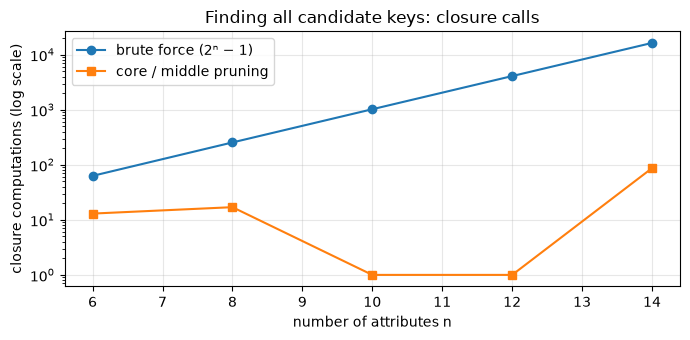

In [11]:
# How much does the pruning save? Count closure computations on bigger relations.
records = []
for n in range(6, 15, 2):
    R_ = "ABCDEFGHIJKLMNOP"[:n]
    rng = random.Random(n)
    F_ = random_fds(R_, n, max_lhs=2, rng=rng)
    s1, s2 = {}, {}
    k1 = candidate_keys(R_, F_, s1)
    k2 = candidate_keys_bruteforce(R_, F_, s2) if n <= 12 else k1
    assert k1 == k2
    records.append({"n attributes": n, "brute force": 2 ** n - 1, "pruned": s1["closure_calls"],
                    "keys found": len(k1)})
calls = pd.DataFrame(records)
print(calls.to_string(index=False))

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.semilogy(calls["n attributes"], calls["brute force"], "o-", label="brute force (2ⁿ − 1)")
ax.semilogy(calls["n attributes"], calls["pruned"], "s-", label="core / middle pruning")
ax.set_xlabel("number of attributes n"); ax.set_ylabel("closure computations (log scale)")
ax.set_title("Finding all candidate keys: closure calls"); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

**What just happened?** On every random relation, the pruned search needed far fewer closure computations than brute force (see the table), while returning exactly the same keys (asserted).

**Complexity.** In the worst case a relation can have exponentially many candidate keys (e.g. R = A₁B₁…AₖBₖ with Aᵢ → Bᵢ and Bᵢ → Aᵢ has 2ᵏ keys), so no algorithm is polynomial in general; deciding whether a relation has a key of size ≤ k is NP-complete (Lucchesi and Osborn, 1978). Pruning makes typical cases fast: the search is over 2^|middle| sets instead of 2^|R|.

### Prime vs. non-prime attributes

- An attribute is **prime** if it belongs to *some* candidate key.
- Otherwise it is **non-prime**.

For F1 above every attribute is prime (keys A, E, BC, CD). For the GATE relation the non-prime attribute is C only. This distinction is the heart of 2NF and 3NF.

> ⚠️ **Common mistake:** "prime" means "in **some** candidate key", not "in the primary key". The primary key is just the candidate key the designer happened to choose.

## 5. F⁺, equivalence of FD sets, and the canonical / minimal cover

> 💡 **In plain English:** different sets of rules can mean exactly the same thing, and a minimal cover is a tidy version with nothing extra.

### F⁺ (briefly)
The **closure of F**, written **F⁺**, is the set of *all* FDs implied by F. It is huge: for every subset X of R and every subset Y of X⁺, X → Y is in F⁺. We almost never compute it; we compute attribute closures instead.

In [12]:
def fd_closure(R, F):
    "All FDs X -> Y (X, Y non-empty) in F+. Exponential: tiny examples only."
    R = sorted(attrs(R))
    out = []
    for k in range(1, len(R) + 1):
        for X in combinations(R, k):
            Xp = sorted(closure(X, F))
            for m in range(1, len(Xp) + 1):
                for Y in combinations(Xp, m):
                    out.append((frozenset(X), frozenset(Y)))
    return out

Fp = fd_closure("ABC", parse_fds("A->B; B->C"))
nontrivial = [f for f in Fp if not is_trivial(f)]
print(f"|F| = 2 but |F+| = {len(Fp)} (of which {len(nontrivial)} are non-trivial)")
print("non-trivial members:", ", ".join(fmt_fd(f) for f in nontrivial))
assert len(Fp) == 35

|F| = 2 but |F+| = 35 (of which 16 are non-trivial)
non-trivial members: A → B, A → C, A → AB, A → AC, A → BC, A → ABC, B → C, B → BC, AB → C, AB → AC, AB → BC, AB → ABC, AC → B, AC → AB, AC → BC, AC → ABC


### Equivalence of FD sets

Two FD sets F and G are **equivalent** (F ≡ G, also "G covers F") if F⁺ = G⁺. Test: every FD of F is implied by G (check with closure under G), and every FD of G is implied by F.

In [13]:
def implies(F, fd):
    "Does F imply the FD fd = (X, Y)?"
    return fd[1] <= closure(fd[0], F)


def equivalent(F, G, explain=False):
    "F and G are equivalent iff each implies every FD of the other."
    missing_in_G = [f for f in F if not implies(G, f)]
    missing_in_F = [g for g in G if not implies(F, g)]
    if explain:
        print("  G fails to imply:", [fmt_fd(f) for f in missing_in_G] or "nothing")
        print("  F fails to imply:", [fmt_fd(g) for g in missing_in_F] or "nothing")
    return not missing_in_G and not missing_in_F


Fa = parse_fds("A->C; AC->D; E->AD; E->H")       # classic textbook pair (Elmasri exercise)
Ga = parse_fds("A->CD; E->AH")
print("F ≡ G ?", equivalent(Fa, Ga, explain=True))
Gb = parse_fds("A->C; E->AH")                     # drop D: no longer equivalent
print("F ≡ G' ?", equivalent(Fa, Gb, explain=True))
assert equivalent(Fa, Ga) and not equivalent(Fa, Gb)

  G fails to imply: nothing
  F fails to imply: nothing
F ≡ G ? True
  G fails to imply: ['AC → D', 'E → AD']
  F fails to imply: nothing
F ≡ G' ? False


### Canonical cover (Silberschatz) / minimal cover (Elmasri)

A **minimal cover** of F is an FD set F_c equivalent to F such that
1. every RHS is a **single attribute**;
2. no LHS has an **extraneous attribute** (A ∈ X is extraneous in X → B if (X − A) → B is already implied by F);
3. no FD is **redundant** (removing it changes the closure).

The **canonical cover** of Silberschatz et al. is the same thing with FDs that share a LHS merged by the union rule (A → B, A → C becomes A → BC). Algorithm:

| step | action | test |
|---|---|---|
| 1 | split every RHS into single attributes, drop trivial parts | |
| 2 | for each FD X → B and each A ∈ X: drop A if B ∈ (X − A)⁺ under the current set | closure |
| 3 | for each FD f: drop f if its RHS ⊆ LHS⁺ under (current set − f) | closure |

The order of steps 2 and 3 matters: removing extraneous attributes first is what guarantees the result is minimal.

In [14]:
def minimal_cover(F, verbose=False):
    "Minimal cover: single-attribute RHS, no extraneous LHS attributes, no redundant FDs."
    G = []
    for X, Y in F:                                           # step 1: split RHS
        for b in sorted(Y - X):
            if (X, frozenset([b])) not in G:
                G.append((X, frozenset([b])))
    if verbose: print("step 1 (split RHS):         ", fmt_fds(G))
    for i in range(len(G)):                                  # step 2: extraneous LHS attributes
        X, Y = G[i]
        for a in sorted(X):
            if len(X) > 1 and Y <= closure(X - {a}, G):      # (X-a)+ still gives Y
                X = X - {a}
                G[i] = (X, Y)                                # keep G equivalent as we go
    G = list(dict.fromkeys(G))                               # remove duplicates, keep order
    if verbose: print("step 2 (extraneous LHS):    ", fmt_fds(G))
    for fd in list(G):                                       # step 3: redundant FDs
        rest = [g for g in G if g != fd]
        if implies(rest, fd):
            G = rest
    if verbose: print("step 3 (redundant FDs):     ", fmt_fds(G))
    return G


def canonical_cover(F, verbose=False):
    "Minimal cover with equal left-hand sides merged (union rule)."
    merged = {}
    for X, Y in minimal_cover(F, verbose):
        merged[X] = merged.get(X, frozenset()) | Y
    return list(merged.items())


def is_minimal(F):
    "Check the three conditions of a minimal cover."
    single = all(len(Y) == 1 and not Y <= X for X, Y in F)
    no_extr = all(not implies(F, (X - {a}, Y)) for X, Y in F for a in X if len(X) > 1)
    no_red = all(not implies([g for g in F if g != f], f) for f in F)
    return single and no_extr and no_red


print("Silberschatz:  F = { A→BC, B→C, A→B, AB→C }")
Fc = canonical_cover(parse_fds("A->BC; B->C; A->B; AB->C"), verbose=True)
print("canonical cover:", fmt_fds(Fc))
assert set(Fc) == set(parse_fds("A->B; B->C"))

print("\nElmasri:  E = { B→A, D→A, AB→D }")
Mc = minimal_cover(parse_fds("B->A; D->A; AB->D"), verbose=True)
assert set(Mc) == set(parse_fds("B->D; D->A"))

Silberschatz:  F = { A→BC, B→C, A→B, AB→C }
step 1 (split RHS):          { A → B,  A → C,  B → C,  AB → C }
step 2 (extraneous LHS):     { A → B,  A → C,  B → C }
step 3 (redundant FDs):      { A → B,  B → C }
canonical cover: { A → B,  B → C }

Elmasri:  E = { B→A, D→A, AB→D }
step 1 (split RHS):          { B → A,  D → A,  AB → D }
step 2 (extraneous LHS):     { B → A,  D → A,  B → D }
step 3 (redundant FDs):      { D → A,  B → D }


In [15]:
# Minimal covers are NOT unique: the result depends on the order of the input FDs.
F_cyc = parse_fds("A->BC; B->AC; C->AB")
c1 = minimal_cover(F_cyc)
c2 = minimal_cover(list(reversed(F_cyc)))
print("cover 1:", fmt_fds(c1)); print("cover 2:", fmt_fds(c2))
assert equivalent(c1, c2) and equivalent(c1, F_cyc) and is_minimal(c1) and is_minimal(c2)

# Random tests: the cover is equivalent to F and satisfies all three conditions
for trial in range(300):
    F_ = random_fds("ABCDEF", random.randint(1, 7))
    M = minimal_cover(F_)
    assert equivalent(M, F_) and is_minimal(M), fmt_fds(F_)
print("minimal_cover: equivalent and minimal on 300 random FD sets")

cover 1: { A → C,  B → C,  C → A,  C → B }
cover 2: { C → B,  B → A,  A → C }
minimal_cover: equivalent and minimal on 300 random FD sets


**What just happened?**
- Silberschatz's example: A → BC splits into A → B, A → C; in AB → C the attribute A is extraneous (B → C already gives it), which makes it a copy of B → C; then A → C is redundant because A → B → C. Result {A → B, B → C}.
- Elmasri's example: in AB → D, B is enough on its own (B → A gives AB), so it becomes B → D; then B → A is redundant (B → D → A). Result {B → D, D → A}.
- The cyclic example has two different minimal covers, both correct; they do not even have the same number of FDs (4 and 3). "Minimal" means nothing can be removed, not "smallest possible". In an exam, any correct minimal cover gets full marks.

**Complexity.** Step 2 and step 3 each do O(|F| · a) closure computations, each polynomial, so the whole algorithm is polynomial in |F| and |R|.

## 6. Normal forms

> 💡 **In plain English:** normal forms are levels of tidiness; each level removes one more way a fact can be stored in the wrong place.

A **normal form** is a condition on a relation schema (and its dependencies) that rules out a certain kind of redundancy. Higher normal forms are stricter:

**1NF ⊃ 2NF ⊃ 3NF ⊃ BCNF ⊃ 4NF ⊃ 5NF (PJNF) ⊃ DKNF**

Each step forbids one more kind of "fact stored in the wrong place".

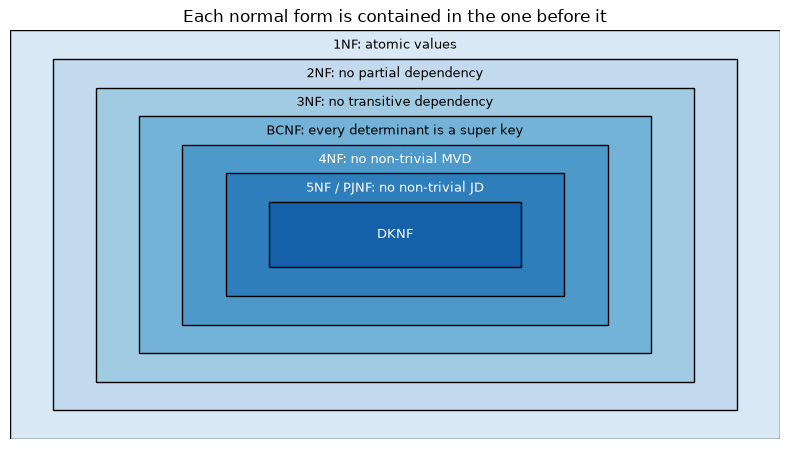

In [16]:
fig, ax = plt.subplots(figsize=(8, 4.6))
levels = ["1NF: atomic values", "2NF: no partial dependency", "3NF: no transitive dependency",
          "BCNF: every determinant is a super key", "4NF: no non-trivial MVD", "5NF / PJNF: no non-trivial JD",
          "DKNF"]
step = 0.07                                                   # thickness of each band
for i, label in enumerate(levels):
    x0, y0 = i * step * 0.8, i * step
    ax.add_patch(plt.Rectangle((x0, y0), 1 - 2 * x0, 1 - 2 * y0, color=plt.cm.Blues(0.15 + i * 0.11), ec="black"))
    y_text = 1 - y0 - step / 2 if i < len(levels) - 1 else 0.5      # inside the band; DKNF in the centre
    ax.text(0.5, y_text, label, ha="center", va="center", fontsize=9, color="white" if i >= 4 else "black")
ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.axis("off")
ax.set_title("Each normal form is contained in the one before it")
plt.tight_layout(); plt.show()

### 6.1 First normal form (1NF)

**Definition.** A relation is in **1NF** if the domain of every attribute contains only **atomic** (indivisible) values, and each attribute holds a single value of that domain. That forbids:
- **multivalued attributes** (a cell containing "555-1111, 555-2222"), and
- **repeating groups** (columns `phone1`, `phone2`, `phone3`, or a nested table inside a row).

Why it matters: you cannot index, join or constrain the inside of a comma-separated string, and "the third phone" has no meaning.

**Fix.** Move the multivalued attribute into its own relation with a foreign key to the owner (one row per value).

In [17]:
nf1 = sqlite3.connect(":memory:")
nf1.execute("CREATE TABLE student_bad (sid INTEGER PRIMARY KEY, name TEXT, phones TEXT)")
nf1.executemany("INSERT INTO student_bad VALUES (?,?,?)",
                [(1, "Ayesha", "0300-1111, 0321-2222"), (2, "Bilal", "0333-3333"), (3, "Chen", "")])
print("Violates 1NF (a list stored in one cell):")
print(q(nf1, "SELECT * FROM student_bad"))
# Question: who has phone 0321-2222? Only a fragile LIKE search works:
print("\nLIKE search:", q(nf1, "SELECT name FROM student_bad WHERE phones LIKE '%0321-2222%'").name.tolist())

# Fix: one row per (student, phone). pandas 'explode' does the reshaping for us.
df = q(nf1, "SELECT * FROM student_bad")
df["phone"] = df["phones"].str.split(r",\s*")
phones = df.explode("phone").query("phone != ''")[["sid", "phone"]]
nf1.execute("CREATE TABLE student (sid INTEGER PRIMARY KEY, name TEXT)")
nf1.execute("CREATE TABLE student_phone (sid INTEGER REFERENCES student(sid), phone TEXT, PRIMARY KEY (sid, phone))")
nf1.executemany("INSERT INTO student VALUES (?,?)", df[["sid", "name"]].values.tolist())
nf1.executemany("INSERT INTO student_phone VALUES (?,?)", phones.values.tolist())
print("\n1NF version:\n", q(nf1, "SELECT * FROM student_phone"))
print("\nEquality search:", q(nf1, '''SELECT name FROM student JOIN student_phone USING (sid)
                                       WHERE phone = '0321-2222' ''').name.tolist())

Violates 1NF (a list stored in one cell):
   sid    name                phones
0    1  Ayesha  0300-1111, 0321-2222
1    2   Bilal             0333-3333
2    3    Chen                      

LIKE search: ['Ayesha']

1NF version:
    sid      phone
0    1  0300-1111
1    1  0321-2222
2    2  0333-3333

Equality search: ['Ayesha']


**What just happened?** The non-1NF table forced a `LIKE '%…%'` text search (slow, cannot use an index, and would wrongly match "10321-2222"). After splitting phones into their own table, the question is an ordinary equality join. The repeating-group version (`phone1, phone2, phone3`) is fixed the same way.

From here on, all relations are assumed to be in 1NF; the higher normal forms are about **dependencies between attributes**.

### 6.2 Second normal form (2NF)

**Full vs. partial dependency.** X → A is a **full functional dependency** if removing any attribute from X breaks it; otherwise it is **partial**.

**Definition.** R is in **2NF** if it is in 1NF and **every non-prime attribute is fully functionally dependent on every candidate key** (no non-prime attribute depends on a *proper part* of a key).

2NF only matters when some key has two or more attributes; a relation whose keys are all single attributes is automatically in 2NF.

**Violation example** (Elmasri): `EMP_PROJ(Ssn, Pnumber, Hours, Ename, Pname, Plocation)` with
FD1: {Ssn, Pnumber} → Hours, FD2: Ssn → Ename, FD3: Pnumber → {Pname, Plocation}.
The only key is {Ssn, Pnumber}; Ename depends on just Ssn (part of the key), so it is repeated for every project the employee works on.

**Fix (2NF normalization):** put each partial dependency in its own relation: EP1(Ssn, Pnumber, Hours), EP2(Ssn, Ename), EP3(Pnumber, Pname, Plocation).

In [18]:
def project_fds(Ri, F):
    "A cover of the FDs of F+ that involve only attributes of Ri (exponential in |Ri|)."
    Ri = attrs(Ri)
    out = []
    for k in range(1, len(Ri)):
        for X in combinations(sorted(Ri), k):
            Y = (closure(X, F) & Ri) - set(X)            # what X determines inside Ri
            if Y:
                out.append((frozenset(X), frozenset(Y)))
    return minimal_cover(out)


def fds_on(R, F):
    "FDs to use when reasoning about R alone: F itself if it fits inside R, else the projection."
    R = attrs(R)
    return F if all((X | Y) <= R for X, Y in F) else project_fds(R, F)


def split(F):
    "Split every FD into single-attribute RHS FDs, dropping trivial parts."
    return [(X, frozenset([a])) for X, Y in F for a in sorted(Y - X)]


def violations_2nf(R, F):
    "Partial dependencies K' -> A, with K' a proper subset of a candidate key and A non-prime."
    R, G = attrs(R), fds_on(R, F)
    keys = candidate_keys(R, G)
    nonprime = R - frozenset().union(*keys)
    out = []
    for K in keys:
        for k in range(1, len(K)):                           # proper subsets, smallest first
            for S in combinations(sorted(K), k):
                S = frozenset(S)
                dep = (closure(S, G) & nonprime) - S
                for T, D in out:                             # report only minimal LHSs
                    if T < S:
                        dep -= D
                if dep and (S, dep) not in out:
                    out.append((S, dep))
    return out


EMP_PROJ = attrs("Ssn, Pnumber, Hours, Ename, Pname, Plocation")
F_ep = parse_fds("Ssn, Pnumber -> Hours; Ssn -> Ename; Pnumber -> Pname, Plocation")
print("keys:", [fmt(k) for k in candidate_keys(EMP_PROJ, F_ep)])
for X, Y in violations_2nf(EMP_PROJ, F_ep):
    print("partial dependency:", fmt_fd((X, Y)))
assert len(violations_2nf(EMP_PROJ, F_ep)) == 2
for Ri in ["Ssn, Pnumber, Hours", "Ssn, Ename", "Pnumber, Pname, Plocation"]:
    assert violations_2nf(Ri, F_ep) == [], Ri
print("EP1, EP2, EP3 have no partial dependencies -> 2NF")

keys: ['{Pnumber, Ssn}']
partial dependency: Pnumber → {Plocation, Pname}
partial dependency: Ssn → Ename
EP1, EP2, EP3 have no partial dependencies -> 2NF


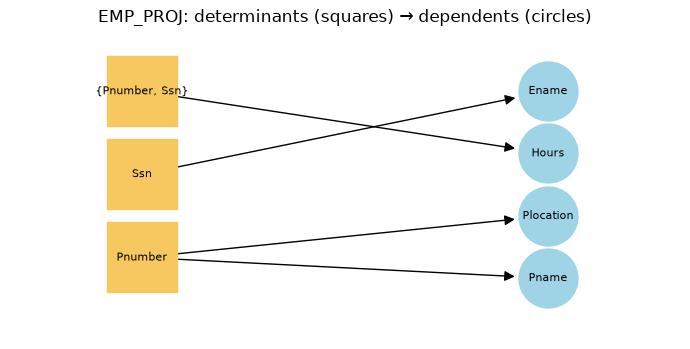

In [19]:
# A dependency diagram (Elmasri style): arrows from each determinant to what it determines
def draw_fds(F, title, ax):
    G = nx.DiGraph()
    lhs_nodes = []
    for X, Y in F:
        src = fmt(X)
        lhs_nodes.append(src)
        for a in Y:
            G.add_edge(src, a)
    rhs_nodes = sorted({a for X, Y in F for a in Y} - set(lhs_nodes))
    lhs_nodes = list(dict.fromkeys(lhs_nodes))
    pos = {n: (0, -i) for i, n in enumerate(lhs_nodes)}
    pos.update({n: (2, -i * len(lhs_nodes) / max(1, len(rhs_nodes))) for i, n in enumerate(rhs_nodes)})
    nx.draw_networkx_nodes(G, pos, nodelist=lhs_nodes, node_color="#f6c85f", node_shape="s", node_size=2600, ax=ax)
    nx.draw_networkx_nodes(G, pos, nodelist=rhs_nodes, node_color="#9fd3e6", node_size=1800, ax=ax)
    nx.draw_networkx_labels(G, pos, font_size=8, ax=ax)
    nx.draw_networkx_edges(G, pos, arrows=True, arrowsize=15, node_size=2300, ax=ax)
    ax.set_title(title); ax.axis("off"); ax.margins(0.25)

fig, ax = plt.subplots(figsize=(7, 3.6))
draw_fds(F_ep, "EMP_PROJ: determinants (squares) → dependents (circles)", ax)
plt.tight_layout(); plt.show()

**What just happened?** `violations_2nf` found the two partial dependencies Ssn → Ename and Pnumber → {Plocation, Pname}, and confirmed the three-way split has none. In the diagram, arrows leaving *part* of the key (Ssn alone, Pnumber alone) are exactly the partial dependencies.

`project_fds` is needed whenever we check a *piece* of a decomposition: the FDs that hold on a sub-relation Rᵢ are those of F⁺ that use only attributes of Rᵢ, not just the FDs of F that happen to fit inside Rᵢ.

### 6.3 Third normal form (3NF)

**Transitive dependency.** X → A is **transitive** if there is a set Y, not a super key, with X → Y and Y → A (and A ∉ Y).

**Definition (Silberschatz / Zaniolo form).** R is in **3NF** if for every non-trivial FD X → A in F⁺ (A a single attribute), at least one holds:
1. X is a **super key** of R, or
2. A is a **prime** attribute.

Equivalently (Codd's form): R is in 2NF and no non-prime attribute is transitively dependent on a candidate key. It is enough to check the FDs of a cover of F, with RHS split.

**Violation example** (Elmasri): `EMP_DEPT(Ename, Ssn, Bdate, Address, Dnumber, Dname, Dmgr_ssn)`, F = {Ssn → {Ename, Bdate, Address, Dnumber}, Dnumber → {Dname, Dmgr_ssn}}. The key is Ssn. Ssn → Dnumber → Dname is transitive: Dnumber is not a super key and Dname is non-prime. This is exactly the table from Section 1.

**Fix:** ED1(Ename, Ssn, Bdate, Address, Dnumber) and ED2(Dnumber, Dname, Dmgr_ssn).

In [20]:
def violations_3nf(R, F):
    "FDs X -> A where X is not a super key and A is not prime."
    R, G = attrs(R), fds_on(R, F)
    prime = prime_attributes(R, G)
    return [(X, Y) for X, Y in split(G) if not is_superkey(X, R, G) and not Y <= prime]


EMP_DEPT = attrs("Ename, Ssn, Bdate, Address, Dnumber, Dname, Dmgr_ssn")
F_ed = parse_fds("Ssn -> Ename, Bdate, Address, Dnumber; Dnumber -> Dname, Dmgr_ssn")
print("keys:", [fmt(k) for k in candidate_keys(EMP_DEPT, F_ed)])
print("2NF violations:", [fmt_fd(f) for f in violations_2nf(EMP_DEPT, F_ed)])
print("3NF violations:", [fmt_fd(f) for f in violations_3nf(EMP_DEPT, F_ed)])
assert violations_2nf(EMP_DEPT, F_ed) == [] and len(violations_3nf(EMP_DEPT, F_ed)) == 2
for Ri in ["Ename, Ssn, Bdate, Address, Dnumber", "Dnumber, Dname, Dmgr_ssn"]:
    assert violations_3nf(Ri, F_ed) == []
print("ED1 and ED2 are in 3NF")

keys: ['Ssn']
2NF violations: []
3NF violations: ['Dnumber → Dmgr_ssn', 'Dnumber → Dname']
ED1 and ED2 are in 3NF


### 6.4 Boyce–Codd normal form (BCNF)

**Definition.** R is in **BCNF** if for every non-trivial FD X → Y in F⁺, **X is a super key** of R. In words: *every determinant is a key*. It is enough to check the FDs of F when F only mentions attributes of R; for a sub-relation, use the projected FDs.

BCNF is 3NF without the escape clause "or A is prime". So every BCNF relation is in 3NF, but not the other way round.

In [21]:
def violations_bcnf(R, F):
    "Non-trivial FDs X -> Y whose LHS is not a super key."
    R, G = attrs(R), fds_on(R, F)
    return [(X, Y - X) for X, Y in G if not Y <= X and not is_superkey(X, R, G)]


def is_2nf(R, F):  return not violations_2nf(R, F)
def is_3nf(R, F):  return not violations_3nf(R, F)
def is_bcnf(R, F): return not violations_bcnf(R, F)


def highest_normal_form(R, F, verbose=False):
    "Highest of 1NF/2NF/3NF/BCNF satisfied by R under F (1NF assumed)."
    if is_bcnf(R, F):
        nf = "BCNF"
    elif is_3nf(R, F):
        nf = "3NF"
    elif is_2nf(R, F):
        nf = "2NF"
    else:
        nf = "1NF"
    if verbose:
        G = fds_on(R, F)
        print(f"R = {fmt(attrs(R))};  keys = {[fmt(k) for k in candidate_keys(R, G)]};"
              f"  prime = {fmt(prime_attributes(R, G))}")
        for name, viol in [("2NF", violations_2nf), ("3NF", violations_3nf), ("BCNF", violations_bcnf)]:
            v = viol(R, F)
            print(f"   {name:4s} violated by: {', '.join(fmt_fd(f) for f in v)}" if v else f"   {name:4s} ok")
        print("   highest normal form:", nf)
    return nf


# Known textbook answers
assert highest_normal_form(EMP_PROJ, F_ep) == "1NF"
assert highest_normal_form(EMP_DEPT, F_ed) == "2NF"
assert highest_normal_form(R_sil, F_sil) == "1NF"           # A -> B with AG the only key
assert highest_normal_form("ABCDE", F1) == "3NF"            # all prime, B -> D breaks BCNF
assert highest_normal_form("ABC", parse_fds("A->B; B->C")) == "2NF"
assert highest_normal_form("AB", parse_fds("A->B")) == "BCNF"

# Hierarchy sanity check on random relations: BCNF => 3NF => 2NF
for trial in range(300):
    R_ = "ABCDEF"[: random.randint(2, 6)]
    F_ = [(X & set(R_), Y & set(R_)) for X, Y in random_fds(R_, random.randint(1, 5))]
    F_ = [(X, Y) for X, Y in F_ if X and Y]
    b, t, s = is_bcnf(R_, F_), is_3nf(R_, F_), is_2nf(R_, F_)
    assert (not b or t) and (not t or s), fmt_fds(F_)
print("normal-form checker: textbook answers OK; BCNF ⊆ 3NF ⊆ 2NF on 300 random relations\n")
highest_normal_form(EMP_DEPT, F_ed, verbose=True)

normal-form checker: textbook answers OK; BCNF ⊆ 3NF ⊆ 2NF on 300 random relations

R = {Address, Bdate, Dmgr_ssn, Dname, Dnumber, Ename, Ssn};  keys = ['Ssn'];  prime = Ssn
   2NF  ok
   3NF  violated by: Dnumber → Dmgr_ssn, Dnumber → Dname
   BCNF violated by: Dnumber → {Dmgr_ssn, Dname}
   highest normal form: 2NF


'2NF'

### 6.5 3NF vs. BCNF, and a case where BCNF loses a dependency

The two forms differ only when a non-key determinant points **into a key** (the RHS attribute is prime). The classic example is Elmasri's `TEACH(Student, Course, Instructor)`:

- FD1: {Student, Course} → Instructor (each student has one instructor per course)
- FD2: Instructor → Course (each instructor teaches one course)

Keys: {Student, Course} and {Student, Instructor}. All attributes are prime, so TEACH **is in 3NF**. FD2's LHS (Instructor) is not a super key, so TEACH is **not in BCNF**.

The BCNF fix is (Instructor, Course) and (Student, Instructor). It is lossless, but **FD1 cannot be checked inside either table**: it spans attributes that are now in different relations. Below, each table accepts the rows (all its own constraints pass) and the join still breaks FD1.

| | 3NF | BCNF |
|---|---|---|
| Condition on X → A | X super key **or** A prime | X super key |
| Redundancy | a little may remain | none caused by FDs |
| Lossless decomposition always possible | yes | yes |
| Dependency-preserving decomposition always possible | **yes** (synthesis) | **no** |

In [22]:
R_teach = attrs("Student, Course, Instructor")
F_teach = parse_fds("Student, Course -> Instructor; Instructor -> Course")
highest_normal_form(R_teach, F_teach, verbose=True)
assert highest_normal_form(R_teach, F_teach) == "3NF"

bc = sqlite3.connect(":memory:")
bc.executescript('''
CREATE TABLE teaches (instructor TEXT PRIMARY KEY, course TEXT NOT NULL);        -- Instructor -> Course
CREATE TABLE studies (student TEXT, instructor TEXT, PRIMARY KEY (student, instructor));
INSERT INTO teaches VALUES ('Mark', 'Database'), ('Navathe', 'Database');
INSERT INTO studies VALUES ('Smith', 'Mark'), ('Smith', 'Navathe');              -- each row is legal
''')
joined = q(bc, "SELECT student AS Student, course AS Course, instructor AS Instructor FROM studies JOIN teaches USING (instructor)")
print("\nBoth BCNF tables accepted their rows. The join is:\n", joined)
print("\n{Student, Course} -> Instructor holds on the join?", holds(joined, "Student, Course", "Instructor"))
assert not holds(joined, "Student, Course", "Instructor")

R = {Course, Instructor, Student};  keys = ['{Course, Student}', '{Instructor, Student}'];  prime = {Course, Instructor, Student}
   2NF  ok
   3NF  ok
   BCNF violated by: Instructor → Course
   highest normal form: 3NF

Both BCNF tables accepted their rows. The join is:
   Student    Course Instructor
0   Smith  Database       Mark
1   Smith  Database    Navathe

{Student, Course} -> Instructor holds on the join? False


**What just happened?** Each BCNF table enforces its own key, and both inserts were legal. But after the join, Smith takes "Database" with two instructors, breaking FD1. To enforce FD1 we would need a join (or a trigger/assertion) on every insert. That is the price of BCNF here; a designer may choose to keep TEACH in 3NF instead.

> 🎓 **Exam tip:** "Is every relation in 3NF also in BCNF?" No. Counterexample: R(A, B, C) with AB → C and C → B (keys AB and AC; C → B has a non-super-key LHS but a prime RHS). "Is every 2-attribute relation in BCNF?" Yes (see practice problem 8).

## 7. Decomposition properties: lossless join and dependency preservation

> 💡 **In plain English:** when you split a table, joining the pieces must give back exactly the original rows, and ideally every rule can still be checked inside one piece.

A **decomposition** of R replaces it by R₁, …, Rₙ with R₁ ∪ … ∪ Rₙ = R. Two properties decide whether it is safe:

1. **Lossless join** (non-additive): for every legal instance r, joining the projections gives back exactly r: π_R₁(r) ⋈ … ⋈ π_Rₙ(r) = r. (The join always contains r; a "lossy" decomposition adds **spurious tuples**, so we lose information about which combinations were real.) This property is **mandatory**.
2. **Dependency preservation:** (F₁ ∪ … ∪ Fₙ)⁺ = F⁺, where Fᵢ are the FDs of F⁺ on Rᵢ. Then every FD can be checked inside a single table, without joins. This property is **desirable**.

### 7.1 The two-relation rule

For a decomposition into exactly two relations: {R₁, R₂} is lossless **iff** (R₁ ∩ R₂) → R₁ or (R₁ ∩ R₂) → R₂ is in F⁺, i.e. the common attributes form a super key of at least one side.

### 7.2 The chase (tableau) test, for any number of relations

1. Build a table with one row per Rᵢ and one column per attribute Aⱼ. Put the distinguished symbol **aⱼ** where Aⱼ ∈ Rᵢ, otherwise a unique **bᵢⱼ**.
2. Repeat until nothing changes: for each FD X → Y, for rows that agree on all X columns, make their Y columns equal (if one of them is an **a**, use the **a**; otherwise pick one **b**). Rename the symbol everywhere in that column.
3. The decomposition is lossless **iff** some row becomes all **a**'s.

The final tableau is in fact a counterexample instance when the test fails: it satisfies F, and its projections join to a tuple (all **a**'s) that is not in it.

In [23]:
def lossless_binary(R1, R2, F):
    "Two-relation rule: the common attributes determine R1 or R2."
    R1, R2 = attrs(R1), attrs(R2)
    c = closure(R1 & R2, F)
    return R1 <= c or R2 <= c


def chase(R, decomposition, F, verbose=False):
    "Tableau (chase) test for a lossless join; returns (lossless?, final tableau)."
    cols = sorted(attrs(R))
    D = [attrs(Ri) for Ri in decomposition]
    T = [[f"a{j+1}" if c in Ri else f"b{i+1}{j+1}" for j, c in enumerate(cols)] for i, Ri in enumerate(D)]
    idx = {c: j for j, c in enumerate(cols)}
    changed = True
    while changed:
        changed = False
        for X, Y in F:
            xs, ys = [idx[a] for a in X], [idx[a] for a in Y]
            for r1 in range(len(T)):
                for r2 in range(r1 + 1, len(T)):
                    if all(T[r1][j] == T[r2][j] for j in xs):        # rows agree on X
                        for j in ys:
                            s1, s2 = T[r1][j], T[r2][j]
                            if s1 != s2:                              # make Y equal
                                keep = s1 if s1.startswith("a") else s2 if s2.startswith("a") else min(s1, s2)
                                drop = s2 if keep == s1 else s1
                                for row in T:                         # rename everywhere in column j
                                    if row[j] == drop:
                                        row[j] = keep
                                changed = True
    lossless = any(all(s.startswith("a") for s in row) for row in T)
    tableau = pd.DataFrame(T, columns=cols, index=[f"R{i+1}" for i in range(len(D))])
    if verbose:
        print(tableau.to_string()); print("lossless" if lossless else "LOSSY (no all-a row)")
    return lossless, tableau


# Elmasri's EMP_PROJ example, two decompositions with known answers
F_emp = parse_fds("Ssn -> Ename; Pnumber -> Pname, Plocation; Ssn, Pnumber -> Hours")
R_emp = attrs("Ssn, Ename, Pnumber, Pname, Plocation, Hours")
D_lossy = ["Ename, Plocation", "Ssn, Pnumber, Hours, Pname, Plocation"]
D_good = ["Ssn, Ename", "Pnumber, Pname, Plocation", "Ssn, Pnumber, Hours"]
print("Decomposition 1:", D_lossy); ok1, _ = chase(R_emp, D_lossy, F_emp, verbose=True)
print("\nDecomposition 2:", D_good); ok2, _ = chase(R_emp, D_good, F_emp, verbose=True)
assert not ok1 and ok2
assert not lossless_binary(*D_lossy, F_emp)

Decomposition 1: ['Ename, Plocation', 'Ssn, Pnumber, Hours, Pname, Plocation']
   Ename Hours Plocation Pname Pnumber  Ssn
R1    a1   b12        a3   b14     b15  b16
R2   b21    a2        a3    a4      a5   a6
LOSSY (no all-a row)

Decomposition 2: ['Ssn, Ename', 'Pnumber, Pname, Plocation', 'Ssn, Pnumber, Hours']
   Ename Hours Plocation Pname Pnumber  Ssn
R1    a1   b12       b13   b14     b15   a6
R2   b21   b22        a3    a4      a5  b26
R3    a1    a2        a3    a4      a5   a6
lossless


In [24]:
# The chase and the two-relation rule must agree on every binary decomposition
for trial in range(400):
    R_ = "ABCDE"
    F_ = random_fds(R_, random.randint(1, 5))
    k = random.randint(1, 4)
    R1 = set(random.sample(R_, k)); R2 = (set(R_) - R1) | set(random.sample(sorted(R1), random.randint(0, len(R1))))
    assert chase(R_, [R1, R2], F_)[0] == lossless_binary(R1, R2, F_)
print("chase == two-relation rule on 400 random binary decompositions")

# And the test is about real data: a lossy decomposition creates spurious tuples
inst = pd.DataFrame({"A": [1, 2], "B": [10, 10], "C": [100, 200]})          # B -> C is NOT true here
j = inst[["A", "B"]].merge(inst[["B", "C"]], on="B")
print("\nR(A,B,C) split on B without B -> C:", len(inst), "rows ->", len(j), "rows after the join (spurious tuples)")
print(j)

chase == two-relation rule on 400 random binary decompositions

R(A,B,C) split on B without B -> C: 2 rows -> 4 rows after the join (spurious tuples)
   A   B    C
0  1  10  100
1  1  10  200
2  2  10  100
3  2  10  200


**What just happened?** Decomposition 1 is lossy: its two relations share only Plocation, which determines nothing, so no row of the tableau becomes all a's. Decomposition 2 is lossless: the chase fills row 3 (WORKS_ON) with a's using Ssn → Ename and Pnumber → {Pname, Plocation}. Both answers match Elmasri and Navathe. The tiny pandas example shows what "lossy" means on data: joining back invented two rows that were never there.

### 7.3 Dependency preservation test

Computing every Fᵢ is exponential. Silberschatz et al. give a polynomial test for each X → Y in F:

```
result := X
repeat
    for each Rᵢ in the decomposition:
        result := result ∪ ((result ∩ Rᵢ)⁺ ∩ Rᵢ)        -- closure under F
until result does not change
X → Y is preserved  iff  Y ⊆ result
```

In [25]:
def preserves_dependencies(F, decomposition, verbose=False):
    "Polynomial test: is every FD of F implied by the union of the projected FDs?"
    D = [attrs(Ri) for Ri in decomposition]
    lost = []
    for X, Y in F:
        result = set(X)
        changed = True
        while changed:
            changed = False
            for Ri in D:
                t = closure(result & Ri, F) & Ri          # what we can derive inside Ri
                if not t <= result:
                    result |= t
                    changed = True
        if not Y <= result:
            lost.append((X, Y))
    if verbose:
        print("preserved" if not lost else "NOT preserved; lost: " + ", ".join(fmt_fd(f) for f in lost))
    return not lost, lost


def preserves_bruteforce(F, decomposition):
    "Reference: project F onto every Ri, union, and compare closures."
    union = [fd for Ri in decomposition for fd in project_fds(Ri, F)]
    return equivalent(union, F)


Fabc = parse_fds("A->B; B->C")
print("R(A,B,C), F = {A→B, B→C}")
for D in [["AB", "BC"], ["AB", "AC"]]:
    print(f"  {D}: lossless = {chase('ABC', D, Fabc)[0]};  ", end="")
    preserves_dependencies(Fabc, D, verbose=True)
assert preserves_dependencies(Fabc, ["AB", "BC"])[0] and not preserves_dependencies(Fabc, ["AB", "AC"])[0]
assert preserves_dependencies(F_teach, ["Instructor, Course", "Student, Instructor"])[1] == [F_teach[0]]

for trial in range(300):
    F_ = random_fds("ABCDE", random.randint(1, 5))
    D = [set(random.sample("ABCDE", random.randint(2, 4))) for _ in range(random.randint(2, 3))]
    D[-1] |= set("ABCDE") - set().union(*D)
    assert preserves_dependencies(F_, D)[0] == preserves_bruteforce(F_, D)
print("\npolynomial test == brute-force projection test on 300 random decompositions")

R(A,B,C), F = {A→B, B→C}
  ['AB', 'BC']: lossless = True;  preserved
  ['AB', 'AC']: lossless = True;  NOT preserved; lost: B → C



polynomial test == brute-force projection test on 300 random decompositions


**What just happened?** For F = {A → B, B → C}, both splits are lossless (B → C makes {AB, BC} lossless; A → B makes {AB, AC} lossless), but only {AB, BC} keeps B → C checkable inside one table. In {AB, AC}, checking B → C would need a join. The fast test agrees with the slow "project everything" definition on all random cases.

**Complexity.** The chase is polynomial: at most O(n · |R|) renamings, each found by scanning row pairs. The dependency-preservation test does O(|F| · n · |R|) closure computations, versus exponential time for projecting F onto every Rᵢ.

## 8. The two design algorithms

> 💡 **In plain English:** two step-by-step recipes split a messy table automatically: one reaches BCNF, the other reaches 3NF without losing any rule.

### 8.1 BCNF decomposition (analysis)

```
result := {R}
while some Rᵢ in result is not in BCNF:
    pick a non-trivial X → Y that holds on Rᵢ with X not a super key of Rᵢ
    replace Rᵢ by  (X ∪ Y)  and  (Rᵢ − (Y − X))          -- we use Y = X⁺ ∩ Rᵢ
```

Each split is lossless by the two-relation rule (the common part X determines X ∪ Y), so the final result is **always lossless** and every piece is in BCNF. It may **not preserve dependencies**, and the result depends on which violation is picked first. To find violations inside a piece Rᵢ we test the given FDs first (as you would by hand), then every subset X of Rᵢ: X violates BCNF in Rᵢ if X⁺ ∩ Rᵢ adds something to X but is not all of Rᵢ.

In [26]:
def find_bcnf_violation(Ri, F):
    "A pair (X, X+ ∩ Ri) that violates BCNF inside Ri, or None."
    Ri = attrs(Ri)
    candidates = [X for X, _ in F if X <= Ri]                       # given FDs first (hand method)
    candidates += [frozenset(S) for k in range(1, len(Ri)) for S in combinations(sorted(Ri), k)]
    for X in candidates:
        Xp = closure(X, F) & Ri
        if Xp != X and Xp != Ri:                                     # adds something, but not a key
            return X, Xp
    return None


def bcnf_decompose(R, F, verbose=False):
    "Lossless BCNF decomposition (repeatedly split on a violating FD)."
    result = [attrs(R)]
    while True:
        for i, Ri in enumerate(result):
            v = find_bcnf_violation(Ri, F)
            if v:
                break
        else:
            return result                                            # no violations left
        X, Xp = v
        R1, R2 = Xp, Ri - (Xp - X)
        if verbose:
            print(f"  {fmt(Ri)} violates BCNF on {fmt_fd((X, Xp - X))}  ->  {fmt(R1)} + {fmt(R2)}")
        result[i:i + 1] = [R1, R2]


# Silberschatz's 'class' relation; the textbook result is course / classroom / section
R_class = attrs("course_id, title, dept_name, credits, sec_id, semester, year, building, room_number, capacity, time_slot_id")
F_class = parse_fds('''course_id -> title, dept_name, credits
building, room_number -> capacity
course_id, sec_id, semester, year -> building, room_number, time_slot_id''')
D_class = bcnf_decompose(R_class, F_class, verbose=True)
for Ri in D_class:
    print("   ", fmt(Ri))
assert set(D_class) == {attrs("course_id, title, dept_name, credits"), attrs("building, room_number, capacity"),
                        attrs("course_id, sec_id, semester, year, building, room_number, time_slot_id")}
assert chase(R_class, D_class, F_class)[0]

  {building, capacity, course_id, credits, dept_name, room_number, sec_id, semester, time_slot_id, title, year} violates BCNF on course_id → {credits, dept_name, title}  ->  {course_id, credits, dept_name, title} + {building, capacity, course_id, room_number, sec_id, semester, time_slot_id, year}
  {building, capacity, course_id, room_number, sec_id, semester, time_slot_id, year} violates BCNF on {building, room_number} → capacity  ->  {building, capacity, room_number} + {building, course_id, room_number, sec_id, semester, time_slot_id, year}
    {course_id, credits, dept_name, title}
    {building, capacity, room_number}
    {building, course_id, room_number, sec_id, semester, time_slot_id, year}


### 8.2 3NF synthesis (Bernstein's algorithm)

```
Fc := a canonical cover of F
for each X → Y in Fc:  create schema (X ∪ Y)
if no schema contains a candidate key of R:  add one candidate key as a schema
remove any schema that is a subset of another
```

The result is **always lossless, dependency-preserving and in 3NF** (Bernstein, 1976; Silberschatz Section 7.5). That is why 3NF is the usual practical target.

In [27]:
def synthesize_3nf(R, F, verbose=False):
    "Bernstein 3NF synthesis: lossless, dependency-preserving, 3NF."
    R = attrs(R)
    Fc = canonical_cover(F)
    if verbose: print("  canonical cover:", fmt_fds(Fc))
    schemas = []
    for X, Y in Fc:
        S = X | Y
        if S not in schemas:
            schemas.append(S)
    if not any(is_superkey(S, R, F) for S in schemas):              # keep the join lossless
        key = candidate_keys(R, F)[0]
        if verbose: print("  no schema contains a key; adding", fmt(key))
        schemas.append(key)
    return [S for S in schemas if not any(S < T for T in schemas)]   # drop subsets


# Silberschatz's cust_banker_branch example
R_cbb = attrs("customer_id, employee_id, branch_name, type")
F_cbb = parse_fds('''customer_id, employee_id -> branch_name, type
employee_id -> branch_name
customer_id, branch_name -> employee_id''')
D_cbb = synthesize_3nf(R_cbb, F_cbb, verbose=True)
for Ri in D_cbb:
    print("   ", fmt(Ri))
assert set(D_cbb) == {attrs("customer_id, employee_id, type"), attrs("customer_id, branch_name, employee_id")}

  canonical cover: { employee_id → branch_name,  {customer_id, employee_id} → type,  {branch_name, customer_id} → employee_id }
    {customer_id, employee_id, type}
    {branch_name, customer_id, employee_id}


In [28]:
# Random verification of the guarantees of both algorithms
stats = {"BCNF lost an FD": 0, "trials": 0}
for trial in range(250):
    R_ = "ABCDEF"[: random.randint(3, 6)]
    F_ = [(X, Y) for X, Y in random_fds(R_, random.randint(1, 5)) if not Y <= X]
    if not F_:
        continue
    stats["trials"] += 1
    B = bcnf_decompose(R_, F_)
    assert all(is_bcnf(Ri, F_) for Ri in B) and chase(R_, B, F_)[0]               # BCNF + lossless
    stats["BCNF lost an FD"] += not preserves_dependencies(F_, B)[0]
    T = synthesize_3nf(R_, F_)
    assert all(is_3nf(Ri, F_) for Ri in T)                                       # 3NF
    assert chase(R_, T, F_)[0] and preserves_dependencies(F_, T)[0]              # lossless + preserving
print(stats)
print("BCNF decomposition: always BCNF and lossless. 3NF synthesis: always 3NF, lossless and dependency-preserving.")

{'BCNF lost an FD': 67, 'trials': 224}
BCNF decomposition: always BCNF and lossless. 3NF synthesis: always 3NF, lossless and dependency-preserving.


**What just happened?** On every random relation both algorithms kept their promises (asserted), and the counter printed above shows in how many cases the BCNF decomposition lost at least one FD (3NF synthesis never did). That trade-off is the whole 3NF-vs-BCNF story in one number.

| Algorithm | Output in | Lossless | Preserves FDs | Time |
|---|---|---|---|---|
| BCNF decomposition | BCNF | always | not always | exponential in the worst case (testing BCNF of a projection is co-NP-complete) |
| 3NF synthesis | 3NF | always | always | polynomial (canonical cover + one key search) |

(Our `candidate_keys` call inside synthesis is exponential in the worst case, but any single key can be found in polynomial time by shrinking R one attribute at a time.)

## 9. Beyond functional dependencies: 4NF, 5NF and DKNF

> 💡 **In plain English:** some repetition has nothing to do with simple dependencies, such as an employee's unrelated lists of projects and dependents; 4NF and 5NF deal with it.

### 9.1 Multivalued dependencies and 4NF

**Intuition.** An employee works on a *set* of projects and has a *set* of dependents, and the two sets have nothing to do with each other. If we store `EMP(Ename, Pname, Dname)`, every project must be paired with every dependent, so the data is redundant even though there is **no** non-trivial FD at all (the only key is all three attributes, so EMP is in BCNF).

**Definition.** A **multivalued dependency (MVD)** X ↠ Y holds on R (with Z = R − X − Y) if, whenever two tuples agree on X, the tuple obtained by taking Y from one and Z from the other is also in the relation. Equivalently, for each X value, the set of (Y, Z) combinations is the Cartesian product of its Y values and its Z values.

- X ↠ Y is **trivial** if Y ⊆ X or X ∪ Y = R.
- Every FD is an MVD (X → Y implies X ↠ Y), and X ↠ Y implies X ↠ Z (complementation).

**Definition.** R is in **4NF** if for every non-trivial MVD X ↠ Y in the closure, X is a super key. **Fix:** split into (X ∪ Y) and (X ∪ Z); this is lossless exactly when X ↠ Y holds (Fagin, 1977).

In [29]:
def mvd_holds(df, X, Y):
    "Does X ->> Y hold on df? (each X-group must be the product of its Y-values and Z-values)."
    X, Y = sorted(attrs(X)), sorted(attrs(Y) - attrs(X))
    Z = [c for c in df.columns if c not in X and c not in Y]
    if not Y or not Z:
        return True                                                   # trivial MVD
    for _, g in df.groupby(X):
        ys = set(map(tuple, g[Y].values)); zs = set(map(tuple, g[Z].values))
        pairs = set(map(tuple, g[Y + Z].values))
        if pairs != {y + z for y in ys for z in zs}:                  # some combination missing
            return False
    return True


EMP = pd.DataFrame([("Smith", "X", "John"), ("Smith", "Y", "Anna"), ("Smith", "X", "Anna"), ("Smith", "Y", "John"),
                    ("Brown", "W", "Jim"), ("Brown", "X", "Jim"), ("Brown", "Y", "Jim"), ("Brown", "Z", "Jim"),
                    ("Brown", "W", "Joan"), ("Brown", "X", "Joan"), ("Brown", "Y", "Joan"), ("Brown", "Z", "Joan"),
                    ("Brown", "W", "Bob"), ("Brown", "X", "Bob"), ("Brown", "Y", "Bob"), ("Brown", "Z", "Bob")],
                   columns=["Ename", "Pname", "Dname"])
print("EMP has", len(EMP), "rows; Ename ->> Pname holds?", mvd_holds(EMP, "Ename", "Pname"))
print("Ename -> Pname holds?", holds(EMP, "Ename", "Pname"), "| Ename -> Dname holds?", holds(EMP, "Ename", "Dname"))

EMP_PROJECTS = EMP[["Ename", "Pname"]].drop_duplicates()
EMP_DEPENDENTS = EMP[["Ename", "Dname"]].drop_duplicates()
rejoined = EMP_PROJECTS.merge(EMP_DEPENDENTS, on="Ename")
print(f"4NF decomposition: {len(EMP_PROJECTS)} + {len(EMP_DEPENDENTS)} rows instead of {len(EMP)};"
      f" join gives back {len(rejoined)} rows, identical: {set(map(tuple, rejoined.values)) == set(map(tuple, EMP.values))}")
assert mvd_holds(EMP, "Ename", "Pname") and mvd_holds(EMP, "Ename", "Dname")
assert not mvd_holds(EMP.iloc[:3], "Ename", "Pname")     # drop one Smith row -> the MVD is violated

EMP has 16 rows; Ename ->> Pname holds? True
Ename -> Pname holds? False | Ename -> Dname holds? False
4NF decomposition: 6 + 5 rows instead of 16; join gives back 16 rows, identical: True


**What just happened?** By its meaning EMP has no non-trivial FD (its only key is all three attributes, so it is in BCNF), yet Brown's 4 projects × 3 dependents needed 12 rows. The MVD Ename ↠ Pname holds, Ename is not a key, so EMP is not in 4NF. Splitting into EMP_PROJECTS and EMP_DEPENDENTS stores 6 + 5 = 11 rows instead of 16, and the join rebuilds EMP exactly. With three rows of Smith only, the "product" rule fails: that instance does not satisfy the MVD (adding a dependent would have forced extra rows: an insertion anomaly).

### 9.2 Join dependencies and 5NF (PJNF)

**Definition.** A **join dependency (JD)** ⋈(R₁, …, Rₙ) holds on R if every legal instance equals the join of its projections onto R₁, …, Rₙ. An MVD is the special case n = 2. A JD is trivial if some Rᵢ = R.

**Definition.** R is in **5NF**, also called **project-join normal form (PJNF)**, if every non-trivial JD that holds on R is implied by the candidate keys of R.

The textbook example (Elmasri) is `SUPPLY(Sname, Part_name, Proj_name)` with the business rule: *if a supplier supplies a part, and a project uses that part, and the supplier supplies that project, then the supplier supplies that part to that project.* Then SUPPLY is the join of its three binary projections, but **not** of any two of them.

In [30]:
SUPPLY = pd.DataFrame([("Smith", "Bolt", "ProjX"), ("Smith", "Nut", "ProjY"), ("Adamsky", "Bolt", "ProjY"),
                       ("Walton", "Nut", "ProjZ"), ("Adamsky", "Nail", "ProjX"), ("Adamsky", "Bolt", "ProjX"),
                       ("Smith", "Bolt", "ProjY")], columns=["Sname", "Part_name", "Proj_name"])
as_set = lambda d: set(map(tuple, d[["Sname", "Part_name", "Proj_name"]].values))
R1 = SUPPLY[["Sname", "Part_name"]].drop_duplicates()
R2 = SUPPLY[["Sname", "Proj_name"]].drop_duplicates()
R3 = SUPPLY[["Part_name", "Proj_name"]].drop_duplicates()
two_way = R1.merge(R2, on="Sname")
three_way = two_way.merge(R3, on=["Part_name", "Proj_name"])
print("SUPPLY rows:", len(SUPPLY))
print("R1 ⋈ R2      rows:", len(two_way), " spurious:", sorted(as_set(two_way) - as_set(SUPPLY)))
print("R1 ⋈ R2 ⋈ R3 rows:", len(three_way), " equals SUPPLY:", as_set(three_way) == as_set(SUPPLY))
no_mvd = not any(mvd_holds(SUPPLY, a, b) for a in SUPPLY.columns for b in SUPPLY.columns if a != b)
print("No non-trivial MVD with a single-attribute LHS holds (so SUPPLY is in 4NF):", no_mvd)
assert as_set(three_way) == as_set(SUPPLY) and len(two_way) > len(SUPPLY) and no_mvd

SUPPLY rows: 7
R1 ⋈ R2      rows: 9  spurious: [('Adamsky', 'Nail', 'ProjY'), ('Smith', 'Nut', 'ProjX')]
R1 ⋈ R2 ⋈ R3 rows: 7  equals SUPPLY: True
No non-trivial MVD with a single-attribute LHS holds (so SUPPLY is in 4NF): True


**What just happened?** Joining only two projections invented spurious tuples, and no MVD holds, so no binary (MVD-based) split is lossless and SUPPLY is in 4NF. The three-way join rebuilds SUPPLY exactly, so the JD ⋈(R1, R2, R3) holds. Its key is all three attributes, which does not imply this JD, so SUPPLY is not in 5NF; the 5NF design stores the three binary tables. In practice such JDs are rare and hard to spot, which is why most designs stop at BCNF or 4NF.

### 9.3 Domain-key normal form (DKNF)

**Definition (Fagin, 1981).** R is in **DKNF** if every constraint on R is a logical consequence of its **domain constraints** (allowed values of each attribute) and **key constraints**. Then no insert or delete can ever violate a constraint unless it violates a domain or a key, so there are no anomalies of any kind.

Example: in `ACCOUNT(acct_no, type, rate)` with the rule "savings accounts have rate ≥ 2%", the rule is neither a domain nor a key constraint, so the relation is not in DKNF. A DKNF design splits it into `SAVINGS(acct_no, rate ∈ [2%, ∞))` and `CHECKING(acct_no, rate ∈ [0, ∞))`, where the rule *is* a domain constraint. DKNF is a theoretical ideal: there is no general algorithm to reach it, and it is not always achievable.

### Summary of the normal forms

| NF | Condition (beyond the previous NF) | Removes | Typical fix | Lossless & dependency-preserving fix always exists? |
|---|---|---|---|---|
| **1NF** | atomic values, no repeating groups | lists in cells | one row per value | yes |
| **2NF** | no non-prime attribute depends on part of a key | partial dependencies | split off (part-of-key, attrs) | yes |
| **3NF** | for X → A: X super key or A prime | transitive dependencies | split off (X, A) / synthesis | **yes** |
| **BCNF** | for X → Y: X super key | all FD redundancy | BCNF decomposition | lossless yes, preserving **not always** |
| **4NF** | for X ↠ Y non-trivial: X super key | independent multi-valued facts | split (X∪Y), (X∪Z) | lossless yes, preserving not always |
| **5NF / PJNF** | every JD implied by keys | cyclic 3-way facts | split into the JD components | lossless yes |
| **DKNF** | all constraints follow from domains and keys | every anomaly | (no general algorithm) | n/a |

## 10. Five classic exam problems, solved with full output

> 💡 **In plain English:** five typical exam questions, solved by hand and checked by code.

The function `solve` below does what an exam answer should do, in order: keys, prime/non-prime attributes, a minimal cover, the highest normal form with the violating FDs, a BCNF decomposition and a 3NF synthesis, each checked for lossless join and dependency preservation.

In [31]:
def solve(name, R, F, extra_decompositions=()):
    R = attrs(R)
    print("=" * 100)
    print(f"{name}:  R = ({fmt(R)})\n  F = {fmt_fds(F)}")
    keys = candidate_keys(R, F)
    prime = prime_attributes(R, F)
    print(f"  candidate keys : {', '.join(fmt(k) for k in keys)}")
    print(f"  prime          : {fmt(prime)}     non-prime: {fmt(R - prime)}")
    print(f"  minimal cover  : {fmt_fds(minimal_cover(F))}")
    nf = highest_normal_form(R, F)
    for label, viol in [("2NF", violations_2nf), ("3NF", violations_3nf), ("BCNF", violations_bcnf)]:
        v = viol(R, F)
        if v:
            print(f"  {label:4s} violated by : {', '.join(fmt_fd(f) for f in v)}")
    print(f"  HIGHEST NORMAL FORM: {nf}")
    out = {"keys": [fmt(k) for k in keys], "nf": nf}
    for label, D in [("BCNF decomposition", bcnf_decompose(R, F)), ("3NF synthesis", synthesize_3nf(R, F)),
                     *extra_decompositions]:
        D = [attrs(Ri) for Ri in D]
        ll, pres = chase(R, D, F)[0], preserves_dependencies(F, D)
        print(f"  {label}: {[fmt(Ri) for Ri in D]}")
        print(f"      pieces: {[highest_normal_form(Ri, F) for Ri in D]};  lossless: {ll};  "
              f"dependency-preserving: {pres[0]}" + ("" if pres[0] else f" (lost {', '.join(fmt_fd(f) for f in pres[1])})"))
        out[label] = ([fmt(Ri) for Ri in D], ll, pres[0])
    return out

### Problem 1 (GATE-style). R(A, B, C, D, E, H), F = {A → B, BC → D, E → C, D → A}. Find all candidate keys and the highest normal form.

*By hand:* E and H appear on no RHS, so every key contains EH; (EH)⁺ = EHC is not R. Adding one middle attribute: (AEH)⁺, (BEH)⁺ and (DEH)⁺ are all R; (CEH)⁺ = CEH is not. So the keys are AEH, BEH, DEH, and C is the only non-prime attribute. E → C: E is part of a key and C is non-prime, a partial dependency, so R is only in **1NF**.

In [32]:
p1 = solve("Problem 1", "ABCDEH", parse_fds("A->B; BC->D; E->C; D->A"))
assert p1["keys"] == ["AEH", "BEH", "DEH"] and p1["nf"] == "1NF"


Problem 1:  R = (ABCDEH)
  F = { A → B,  BC → D,  E → C,  D → A }
  candidate keys : AEH, BEH, DEH
  prime          : ABDEH     non-prime: C
  minimal cover  : { A → B,  BC → D,  E → C,  D → A }
  2NF  violated by : E → C
  3NF  violated by : E → C
  BCNF violated by : A → B, BC → D, E → C, D → A
  HIGHEST NORMAL FORM: 1NF
  BCNF decomposition: ['AB', 'CE', 'AD', 'DEH']
      pieces: ['BCNF', 'BCNF', 'BCNF', 'BCNF'];  lossless: True;  dependency-preserving: False (lost BC → D)
  3NF synthesis: ['AB', 'BCD', 'CE', 'AD', 'AEH']
      pieces: ['BCNF', '3NF', 'BCNF', 'BCNF', 'BCNF'];  lossless: True;  dependency-preserving: True


### Problem 2 (Silberschatz-style exercise). R(A, B, C, D, E), F = {A → BC, CD → E, B → D, E → A}. List the candidate keys, show that the decomposition (A, B, C), (A, D, E) is lossless, and test whether it preserves dependencies.

*By hand:* keys A, E, BC, CD, so every attribute is prime and R is in **3NF**; B → D has a non-key LHS, so not BCNF. For the decomposition, R₁ ∩ R₂ = A and A⁺ = ABCDE ⊇ R₁, so it is lossless. It does **not** preserve dependencies: B → D is lost (from B we reach only B inside R₁ and nothing inside R₂), and so is CD → E (C⁺ ∩ R₁ = C and D⁺ ∩ R₂ = D add nothing).

In [33]:
p2 = solve("Problem 2", "ABCDE", F1, extra_decompositions=[("Given decomposition", ["ABC", "ADE"])])
assert p2["keys"] == ["A", "E", "BC", "CD"] and p2["nf"] == "3NF"
assert p2["Given decomposition"][1] is True and p2["Given decomposition"][2] is False
assert lossless_binary("ABC", "ADE", F1)

Problem 2:  R = (ABCDE)
  F = { A → BC,  CD → E,  B → D,  E → A }
  candidate keys : A, E, BC, CD
  prime          : ABCDE     non-prime: ∅
  minimal cover  : { A → B,  A → C,  CD → E,  B → D,  E → A }
  BCNF violated by : B → D
  HIGHEST NORMAL FORM: 3NF
  BCNF decomposition: ['BD', 'ABCE']
      pieces: ['BCNF', 'BCNF'];  lossless: True;  dependency-preserving: False (lost CD → E)
  3NF synthesis: ['ABC', 'CDE', 'BD', 'AE']
      pieces: ['BCNF', 'BCNF', 'BCNF', 'BCNF'];  lossless: True;  dependency-preserving: True
  Given decomposition: ['ABC', 'ADE']
      pieces: ['BCNF', 'BCNF'];  lossless: True;  dependency-preserving: False (lost CD → E, B → D)


### Problem 3 (Elmasri's LOTS). LOTS(Property_id, County, Lot_no, Area, Price, Tax_rate) with
FD1: Property_id → all others, FD2: {County, Lot_no} → all others, FD3: County → Tax_rate, FD4: Area → Price.
Normalize to 3NF. Then add FD5: Area → County and discuss BCNF.

*By hand (Elmasri's answer):* keys Property_id and {County, Lot_no}. County → Tax_rate is a partial dependency of the key {County, Lot_no}, so LOTS is in **1NF** only. 2NF: LOTS1(Property_id, County, Lot_no, Area, Price) + LOTS2(County, Tax_rate). LOTS1 has the transitive dependency Area → Price, so 3NF: LOTS1A(Property_id, County, Lot_no, Area) + LOTS1B(Area, Price). With FD5, LOTS1A is still in 3NF (County is prime) but **not BCNF** (Area is not a super key).

In [34]:
R_lots = attrs("Property_id, County, Lot_no, Area, Price, Tax_rate")
F_lots = parse_fds('''Property_id -> County, Lot_no, Area, Price, Tax_rate
County, Lot_no -> Property_id, Area, Price, Tax_rate
County -> Tax_rate
Area -> Price''')
elmasri_3nf = ["Property_id, County, Lot_no, Area", "Area, Price", "County, Tax_rate"]
p3 = solve("Problem 3", R_lots, F_lots, extra_decompositions=[("Elmasri's 3NF design", elmasri_3nf)])
assert p3["nf"] == "1NF" and p3["keys"] == ["Property_id", "{County, Lot_no}"]
assert [highest_normal_form(Ri, F_lots) for Ri in elmasri_3nf] == ["BCNF", "BCNF", "BCNF"]

print("\nWith FD5 Area -> County:")
F_lots5 = F_lots + parse_fds("Area -> County")
highest_normal_form("Property_id, County, Lot_no, Area", F_lots5, verbose=True)
assert highest_normal_form("Property_id, County, Lot_no, Area", F_lots5) == "3NF"

Problem 3:  R = ({Area, County, Lot_no, Price, Property_id, Tax_rate})
  F = { Property_id → {Area, County, Lot_no, Price, Tax_rate},  {County, Lot_no} → {Area, Price, Property_id, Tax_rate},  County → Tax_rate,  Area → Price }
  candidate keys : Property_id, {County, Lot_no}
  prime          : {County, Lot_no, Property_id}     non-prime: {Area, Price, Tax_rate}
  minimal cover  : { Property_id → County,  Property_id → Lot_no,  {County, Lot_no} → Area,  {County, Lot_no} → Property_id,  County → Tax_rate,  Area → Price }
  2NF  violated by : County → Tax_rate
  3NF  violated by : County → Tax_rate, Area → Price
  BCNF violated by : County → Tax_rate, Area → Price
  HIGHEST NORMAL FORM: 1NF
  BCNF decomposition: ['{County, Tax_rate}', '{Area, Price}', '{Area, County, Lot_no, Property_id}']
      pieces: ['BCNF', 'BCNF', 'BCNF'];  lossless: True;  dependency-preserving: True
  3NF synthesis: ['{Area, County, Lot_no, Property_id}', '{County, Tax_rate}', '{Area, Price}']
      pieces: ['BCN

Note that with FD5 a third key appears for LOTS1A: {Area, Lot_no} (Area gives County, then County + Lot_no gives everything). The checker found it automatically.

### Problem 4. R(A, B, C, D), F = {AB → C, C → D, D → A}. Find the keys and the highest normal form; give a BCNF decomposition and say whether it preserves dependencies.

*By hand:* B is in every key. (AB)⁺ = ABCD, (BC)⁺ = BCDA, (BD)⁺ = BDAC, so keys AB, BC, BD; all attributes are prime → **3NF**. C → D and D → A have non-key LHS → not BCNF. Splitting on C → D gives (C, D, A) and (B, C); (C, D, A) still violates via D → A → (D, A), (C, D). Result {AD, CD, BC}: lossless, but AB → C is lost.

In [35]:
p4 = solve("Problem 4", "ABCD", parse_fds("AB->C; C->D; D->A"))
assert p4["keys"] == ["AB", "BC", "BD"] and p4["nf"] == "3NF"
assert set(p4["BCNF decomposition"][0]) == {"AD", "CD", "BC"} and p4["BCNF decomposition"][2] is False

Problem 4:  R = (ABCD)
  F = { AB → C,  C → D,  D → A }
  candidate keys : AB, BC, BD
  prime          : ABCD     non-prime: ∅
  minimal cover  : { AB → C,  C → D,  D → A }
  BCNF violated by : C → D, D → A
  HIGHEST NORMAL FORM: 3NF
  BCNF decomposition: ['AD', 'CD', 'BC']
      pieces: ['BCNF', 'BCNF', 'BCNF'];  lossless: True;  dependency-preserving: False (lost AB → C)
  3NF synthesis: ['ABC', 'CD', 'AD']
      pieces: ['3NF', 'BCNF', 'BCNF'];  lossless: True;  dependency-preserving: True


### Problem 5 (minimal cover + 3NF synthesis). R(A, B, C, D), F = {A → B, C → B, D → ABC, AC → D}. Find a minimal cover and a 3NF design.

*By hand:* split D → ABC into D → A, D → B, D → C. In AC → D, neither A⁺ = AB nor C⁺ = CB contains D, so nothing is extraneous. D → B is redundant (D → A → B). Minimal cover {A → B, C → B, D → A, D → C, AC → D}. Keys D and AC; B is non-prime and A → B is a partial dependency → **1NF**. Synthesis: AB, BC, ACD (the last contains a key), which is 3NF, lossless and dependency-preserving.

In [36]:
F5 = parse_fds("A->B; C->B; D->ABC; AC->D")
p5 = solve("Problem 5", "ABCD", F5)
assert set(minimal_cover(F5)) == set(parse_fds("A->B; C->B; D->A; D->C; AC->D"))
assert p5["keys"] == ["D", "AC"] and p5["nf"] == "1NF"
assert set(p5["3NF synthesis"][0]) == {"AB", "BC", "ACD"} and p5["3NF synthesis"][1:] == (True, True)

Problem 5:  R = (ABCD)
  F = { A → B,  C → B,  D → ABC,  AC → D }
  candidate keys : D, AC
  prime          : ACD     non-prime: B
  minimal cover  : { A → B,  C → B,  D → A,  D → C,  AC → D }
  2NF  violated by : A → B, C → B
  3NF  violated by : A → B, C → B
  BCNF violated by : A → B, C → B
  HIGHEST NORMAL FORM: 1NF
  BCNF decomposition: ['AB', 'ACD']
      pieces: ['BCNF', 'BCNF'];  lossless: True;  dependency-preserving: False (lost C → B)
  3NF synthesis: ['AB', 'BC', 'ACD']
      pieces: ['BCNF', 'BCNF', 'BCNF'];  lossless: True;  dependency-preserving: True


**What just happened?** All five answers match the textbook / hand solutions (asserted). Two patterns are worth remembering:
- BCNF decomposition lost a dependency in problems 2 and 4 (in problem 2 the BCNF design loses CD → E), while 3NF synthesis never does.
- The printed "pieces" line confirms every piece of every decomposition reached the promised normal form.

> 🎓 **Exam tip (a fast recipe):** (1) find the core attributes (never on a RHS); (2) grow keys from the core with closures; (3) mark prime attributes; (4) for each FD X → A: X super key? if not, A prime? if not, is X part of a key (→ 2NF violation) or not (→ 3NF violation)? The *worst* violation decides the highest normal form.

## 11. Denormalization (on purpose) and data replication

> 💡 **In plain English:** sometimes we copy data on purpose to make reading fast, as ML feature tables do, and accept the work of keeping the copies up to date.

**Denormalization** means deliberately storing redundant or pre-joined data to make *reads* faster, accepting the cost of keeping the copies consistent. Normalization optimizes for correct, cheap **writes** (OLTP); analytics and ML mostly **read** big, wide tables (OLAP).

When it is justified:
- **Analytics / data warehouses:** star schemas keep a central fact table plus wide, denormalized dimension tables, so reports need few joins.
- **ML feature tables:** a model wants one row per entity (customer, user, item) with dozens of pre-computed features. Training reads millions of such rows; online inference needs one row in milliseconds. Joining and aggregating raw normalized tables at request time is too slow, so feature pipelines **materialize** the result (this is what a feature store serves).
- **Read-heavy caches:** counters such as "number of orders" stored on the customer row.

The costs are the anomalies of Section 1: when a source value changes, every copy must be refreshed (by a scheduled job, a trigger, or a materialized-view refresh), and readers may briefly see stale values. The rule of thumb: **normalize the source of truth, denormalize derived read models**, and rebuild them from the source.

The demo builds a normalized `customer` / `orders` schema and a denormalized `customer_features` table, then compares fetching features for 1,000 customers both ways.

In [37]:
rng = random.Random(7)
db = sqlite3.connect(":memory:")
db.executescript('''
CREATE TABLE customer (cid INTEGER PRIMARY KEY, city TEXT, signup_year INTEGER);
CREATE TABLE orders   (oid INTEGER PRIMARY KEY, cid INTEGER REFERENCES customer(cid), amount REAL, day INTEGER);
CREATE INDEX orders_cid ON orders(cid);
''')
cities = ["Lahore", "Karachi", "Islamabad", "Peshawar", "Quetta"]
db.executemany("INSERT INTO customer VALUES (?,?,?)",
               [(c, rng.choice(cities), rng.randint(2018, 2025)) for c in range(10_000)])
db.executemany("INSERT INTO orders VALUES (?,?,?,?)",
               [(o, rng.randrange(10_000), round(rng.uniform(5, 500), 2), rng.randint(1, 365)) for o in range(150_000)])

FEATURE_SQL = '''SELECT c.cid, c.city, c.signup_year, COUNT(o.oid) AS n_orders,
                        COALESCE(SUM(o.amount), 0) AS total_spend, COALESCE(AVG(o.amount), 0) AS avg_spend,
                        MAX(o.day) AS last_order_day
                 FROM customer c LEFT JOIN orders o ON o.cid = c.cid
                 WHERE c.cid IN ({ids}) GROUP BY c.cid'''
db.execute("CREATE TABLE customer_features AS " + FEATURE_SQL.replace("WHERE c.cid IN ({ids})", ""))
db.execute("CREATE UNIQUE INDEX cf_cid ON customer_features(cid)")

batch = ",".join(map(str, rng.sample(range(10_000), 1000)))      # a training/inference batch
def timeit(sql, reps=5):
    t = time.perf_counter()
    for _ in range(reps):
        res = db.execute(sql).fetchall()
    return (time.perf_counter() - t) / reps * 1000, res

t_join, r_join = timeit(FEATURE_SQL.format(ids=batch))
t_mat, r_mat = timeit(f"SELECT * FROM customer_features WHERE cid IN ({batch})")
assert sorted(r_join) == sorted(r_mat)                          # same features either way
print(f"compute features with JOIN + GROUP BY : {t_join:7.2f} ms per batch of 1,000 customers")
print(f"read the denormalized feature table   : {t_mat:7.2f} ms per batch")
print(f"speed-up: {t_join / t_mat:.1f}x (identical results)")

# The price: a source change must be propagated, otherwise the feature table is stale
db.execute("INSERT INTO orders VALUES (150000, 42, 999.0, 366)")
fresh = db.execute(FEATURE_SQL.format(ids="42")).fetchone()
stale = db.execute("SELECT * FROM customer_features WHERE cid = 42").fetchone()
print("\ncustomer 42 after a new order -> computed:", fresh[3], "orders; feature table still says:", stale[3])
assert fresh[3] == stale[3] + 1

compute features with JOIN + GROUP BY :   40.38 ms per batch of 1,000 customers
read the denormalized feature table   :    6.61 ms per batch
speed-up: 6.1x (identical results)

customer 42 after a new order -> computed: 15 orders; feature table still says: 14


**What just happened?** Both ways return identical features (asserted). Reading the pre-computed table was faster by the factor printed above, because the join-and-aggregate work was done once, ahead of time. The exact numbers depend on your machine. The last lines show the cost: after a new order, the denormalized table is **stale** until a refresh job recomputes it. Feature stores manage exactly this trade-off (batch refresh, streaming updates, and point-in-time correct joins for training).

### Data replication (briefly)

**Replication** keeps full copies (replicas) of a database on several servers. It is about *availability and read scaling*, not schema design:
- **Leader–follower (primary–replica):** writes go to one leader; followers apply its change log and serve reads.
- **Synchronous** replication waits for replicas before confirming a commit (no data loss on failover, slower writes); **asynchronous** replication confirms immediately (fast, but a follower may lag and return stale reads).
- **Multi-leader / leaderless** setups accept writes in several places and must resolve conflicts.

Denormalization copies data *inside* a schema to avoid joins; replication copies the *whole* database to survive failures and spread load. Both create the same fundamental problem: keeping copies consistent.

## 🔗 How this connects to modern AI

> 💡 **In plain English:** feature stores, data-quality checks and text-to-SQL tools all depend on these design ideas.

- **Feature stores and training tables.** The denormalized feature table above is the pattern behind feature stores: normalized sources, denormalized, versioned feature views. See [Feature stores](../../15_MLOps/12_feature_stores.ipynb) and [SQL for ML feature extraction](../01_sql/02_industry_sql_for_ml_feature_extraction.ipynb).
- **Data quality and profiling.** `holds()` and `discover_fds()` are tiny versions of what data-validation tools do: they check declared FDs (e.g. "`user_id` determines `country`") on each new batch, and FD violations often reveal data-pipeline bugs or label leakage. See [Data contracts](../../15_MLOps/14_data_contracts.ipynb).
- **Leakage through denormalized joins.** Joining a fact table to a dimension that was updated *after* the event (a wide, denormalized table) silently leaks future information into training data; point-in-time joins exist to prevent this.
- **Schema design for ML systems.** Normalized tables for users, models, predictions and feedback make ML systems auditable. See [Relational DB design for ML systems](../../22_ML_System_Design/03_relational_db_design.ipynb) and [Databases in AI](../05_db_in_ai/01_databases_in_ai.ipynb).
- **Knowledge graphs and LLM tools.** Text-to-SQL systems work far better on well-normalized schemas with clear keys, and entity resolution in knowledge graphs is essentially discovering keys and FDs in messy data.

## Recap

> 💡 **In plain English:** the key ideas in a few bullets, for quick revision before the practice problems.

- Mixing facts about different things in one table causes **update, insertion and deletion anomalies**.
- An **FD** X → Y says equal X values force equal Y values in *every* legal instance. Data can refute an FD, never prove it.
- **Armstrong's axioms** (reflexivity, augmentation, transitivity) are sound and complete; union, decomposition and pseudo-transitivity follow.
- **X⁺** decides everything: X → Y iff Y ⊆ X⁺; X is a super key iff X⁺ = R. Candidate keys are found by growing the **core** with **middle** attributes.
- A **minimal / canonical cover** has single-attribute RHS, no extraneous attributes and no redundant FDs; it is not unique.
- **2NF** forbids partial dependencies of non-prime attributes; **3NF** requires X super key *or* A prime; **BCNF** requires X super key.
- Decompositions must be **lossless** (two-relation rule or chase) and should be **dependency-preserving**. **3NF synthesis** always achieves both; **BCNF decomposition** is lossless but may lose FDs.
- **4NF** handles multivalued dependencies, **5NF/PJNF** join dependencies, **DKNF** is the theoretical ideal.
- **Denormalize** derived read models (analytics, ML features) on purpose, keeping a normalized source of truth.

## Practice problems

**1. (Easy)** Which of these are trivial: (a) AB → B, (b) A → AB, (c) AB → AB, (d) ∅ → A?
<details><summary>Show solution</summary>

(a) trivial (B ⊆ AB); (b) non-trivial (B ⊄ A), but not *completely* non-trivial; (c) trivial; (d) non-trivial (it says A is constant in the relation).
</details>

**2. (Easy)** R(A, B, C, D, E, F), F = {AB → C, BC → AD, D → E, CF → B}. Compute (AB)⁺. Is AB a super key?
<details><summary>Show solution</summary>

AB → C gives ABC; BC → AD gives ABCD; D → E gives ABCDE; CF → B needs F, which we never get. (AB)⁺ = ABCDE ≠ R, so AB is **not** a super key (F is missing). `closure("AB", parse_fds("AB->C; BC->AD; D->E; CF->B"))` returns ABCDE.
</details>

**3. (Medium)** Find all candidate keys of R(A, B, C, D) with F = {A → B, B → C, C → A}.
<details><summary>Show solution</summary>

D is on no RHS, so it is in every key; D⁺ = D. A, B, C are all "middle". (AD)⁺ = ABCD, (BD)⁺ = ABCD, (CD)⁺ = ABCD. Keys: **AD, BD, CD**.
</details>

**4. (Medium)** R(A, B, C, D), F = {AB → C, AB → D, C → A, D → B}. What is the highest normal form?
<details><summary>Show solution</summary>

Keys: AB, AD, BC, CD (e.g. (CD)⁺: C → A, D → B, so ABCD). Every attribute is prime, so R is in **3NF**. C → A has a LHS that is not a super key, so it is **not BCNF**. Answer: **3NF**.
</details>

**5. (Medium)** Find a canonical cover of F = {A → BC, B → C, A → B, AB → C} and a 3NF design of R(A, B, C).
<details><summary>Show solution</summary>

Canonical cover {A → B, B → C} (Section 5). Synthesis gives schemas AB and BC; AB contains the key A. Design: **(A, B), (B, C)**, lossless and dependency-preserving.
</details>

**6. (Medium)** R(A, B, C) with F = {A → B}. Is the decomposition (A, B), (B, C) lossless? What if F = {B → C}?
<details><summary>Show solution</summary>

Common attribute B. With F = {A → B}: B⁺ = B contains neither AB nor BC → **lossy**. With F = {B → C}: B⁺ = BC ⊇ (B, C) → **lossless**.
</details>

**7. (Coding)** Write `single_attribute_fds(df)` that returns every FD `a -> b` (a ≠ b, both single columns) satisfied by a DataFrame, as a list of `(a, b)` tuples. Test it on `emp`.
<details><summary>Show solution</summary>

```python
def single_attribute_fds(df):
    out = []
    for a in df.columns:
        for b in df.columns:
            if a != b and (df[[a, b]].drop_duplicates().groupby(a).size() <= 1).all():
                out.append((a, b))
    return out

print(single_attribute_fds(emp))      # includes ('Ssn', 'Ename') and ('Dnumber', 'Dname')
```
</details>

**8. (Hard, proof)** Prove that every relation with exactly two attributes R(A, B) is in BCNF.
<details><summary>Show solution</summary>

The only possible non-trivial FDs are A → B and B → A. Case 1: neither holds; then there is no non-trivial FD and R is in BCNF. Case 2: only A → B holds; then A⁺ = AB, so A is a super key and the FD is allowed. Case 3: only B → A; symmetric. Case 4: both hold; both A and B are keys, so both FDs have super-key LHS. In every case each non-trivial FD has a super key on the left, so R is in BCNF. ∎
</details>

## Further reading

- Silberschatz, Korth and Sudarshan, *Database System Concepts*, 7th ed., Chapter 7 "Relational Database Design" (FDs, closure, canonical cover, BCNF/3NF algorithms, 4NF, 5NF).
- Elmasri and Navathe, *Fundamentals of Database Systems*, 7th ed., Chapter 14 "Basics of Functional Dependencies and Normalization" and Chapter 15 "Relational Database Design Algorithms and Further Dependencies" (minimal covers, the chase, LOTS, SUPPLY).
- Ramakrishnan and Gehrke, *Database Management Systems*, 3rd ed., Chapter 19 "Schema Refinement and Normal Forms".
- GeeksforGeeks DBMS tutorial, sections on functional dependency, attribute closure, normal forms, lossless decomposition and dependency preservation (free, many solved GATE questions).
- Stanford CS145 / CMU 15-445 lecture notes on database design (free online).

## Next notebook

Continue with [05_transactions_and_concurrency_control.ipynb](05_transactions_and_concurrency_control.ipynb): transactions, ACID, schedules, serializability, locking, deadlocks, timestamp ordering and MVCC.